In [132]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project directories
PROJECT_ROOT = Path("..").resolve()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

OUTPUT_DIR = PROJECT_ROOT / "WVS_analysis_output"

REPORT_DIR = PROJECT_ROOT / "report"

In [133]:
# Original WVS dataset
DATA_FILE = RAW_DATA_DIR / "WVS_Cross-National_Wave_7_csv_v6_0.csv"

# Load dataset
df = pd.read_csv(DATA_FILE, low_memory=False)

# Basic overview
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nQ49 target variable:")
print(df["Q49"].describe())

Dataset shape: (97220, 613)

First 5 rows:


,version,doi,A_WAVE,A_YEAR,A_STUDY,B_COUNTRY,B_COUNTRY_ALPHA,C_COW_NUM,C_COW_ALPHA,D_INTERVIEW,...,WVS_Polmistrust_PartyVoter,WVS_LR_MedianVoter,WVS_LibCon_MedianVoter,v2psbars,v2psorgs,v2psprbrch,v2psprlnks,v2psplats,v2xnp_client,v2xps_party
0,6-0-0 (2024-04-30),doi.org/10.14281/18241.24,7,2018,2,20,AND,232,AND,20070001,...,62.434211,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0
1,6-0-0 (2024-04-30),doi.org/10.14281/18241.24,7,2018,2,20,AND,232,AND,20070002,...,62.434211,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0
2,6-0-0 (2024-04-30),doi.org/10.14281/18241.24,7,2018,2,20,AND,232,AND,20070003,...,62.434211,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0
3,6-0-0 (2024-04-30),doi.org/10.14281/18241.24,7,2018,2,20,AND,232,AND,20070004,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,6-0-0 (2024-04-30),doi.org/10.14281/18241.24,7,2018,2,20,AND,232,AND,20070005,...,66.964286,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0



Data types:
int64      406
float64    195
str         12
Name: count, dtype: int64

Q49 target variable:
count    97220.000000
mean         7.012312
std          2.336692
min         -5.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         10.000000
Name: Q49, dtype: float64


In [134]:
# Inspect all Q49 values, including special codes
print("Q49 value counts:")
print(df["Q49"].value_counts(dropna=False).sort_index())

# Identify valid responses
valid_q49 = df["Q49"].between(1, 10)

print("\nQ49 quality check:")
print("Total respondents:", len(df))
print("Valid responses:", valid_q49.sum())
print("Invalid or missing:", (~valid_q49).sum())
print("Valid percentage:", round(valid_q49.mean() * 100, 2), "%")

# Descriptive statistics using valid responses only
print("\nValid Q49 descriptive statistics:")
print(df.loc[valid_q49, "Q49"].describe())

Q49 value counts:
Q49
-5       112
-2       203
-1       205
 1      2632
 2      1421
 3      3140
 4      4476
 5     11530
 6     10986
 7     16377
 8     19689
 9     10097
 10    16352
Name: count, dtype: int64

Q49 quality check:
Total respondents: 97220
Valid responses: 96700
Invalid or missing: 520
Valid percentage: 99.47 %

Valid Q49 descriptive statistics:
count    96700.000000
mean         7.062130
std          2.239034
min          1.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         10.000000
Name: Q49, dtype: float64


In [135]:
# Feature selection directory
FEATURE_SELECTION_DIR = PROJECT_ROOT / "outputs" / "feature_selection"

# Load feature selection results
feature_selection = pd.read_csv(
    FEATURE_SELECTION_DIR / "WVS_Feature_Selection.csv"
)

# Inspect data
print("Feature selection loaded successfully!")
print("Shape:", feature_selection.shape)

display(feature_selection.head())

Feature selection loaded successfully!
Shape: (372, 20)


,Variable,Feature_group,Variable_role,Model_status,Category,Column number,Data type,Missing count (NaN),Missing percentage (NaN),Unique values (excluding NaN),Candidate special-code count,Candidate special-code details,Example values,Preliminary category,Measurement_type,Countries_with_valid_responses,Country_coverage_percentage,Respondents_with_valid_responses,Selection_decision,Selection_reason
0,Q1,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,41,int64,0,0.0,7,155,-1: 27; -2: 61; -5: 67,1 | 2 | 3 | 4 | -2 | -1 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,97065.0,Keep,Measures the importance of a major life domain...
1,Q2,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,42,int64,0,0.0,7,312,-1: 84; -2: 141; -5: 87,1 | 2 | 3 | 4 | -1 | -2 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96908.0,Keep,Measures the importance of a major life domain...
2,Q3,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,43,int64,0,0.0,7,535,-1: 202; -2: 196; -5: 137,1 | 2 | 3 | 4 | -1 | -2 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96685.0,Keep,Measures the importance of a major life domain...
3,Q4,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,44,int64,0,0.0,7,1090,-1: 587; -2: 323; -5: 180,3 | 4 | 2 | 1 | -2 | -1 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96130.0,Keep,Measures the importance of a major life domain...
4,Q5,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,45,int64,0,0.0,7,1160,-1: 368; -2: 289; -5: 503,1 | 3 | 2 | 4 | -2 | -1 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96060.0,Keep,Measures the importance of a major life domain...


In [136]:
# Select variables marked as Keep
keep_features = feature_selection.loc[
    feature_selection["Selection_decision"] == "Keep",
    "Variable"
].tolist()

# Target variable
TARGET = "Q49"

# Check which selected features exist in the raw dataset
available_features = [
    col for col in keep_features
    if col in df.columns and col != TARGET
]

missing_features = [
    col for col in keep_features
    if col not in df.columns
]

print("Keep features in selection file:", len(keep_features))
print("Available predictors:", len(available_features))
print("Missing from raw dataset:", len(missing_features))

if missing_features:
    print("\nMissing variables:")
    print(missing_features)

print("\nTarget in predictors:", TARGET in available_features)

Keep features in selection file: 248
Available predictors: 248
Missing from raw dataset: 0

Target in predictors: False


In [137]:
import numpy as np

# Create a separate modeling dataset
model_df = df[available_features + [TARGET]].copy()

# Convert invalid target codes to NaN
model_df[TARGET] = model_df[TARGET].where(
    model_df[TARGET].between(1, 10),
    np.nan
)

# Keep respondents with valid target values
model_df = model_df.dropna(subset=[TARGET]).copy()

print("Modeling dataset shape:", model_df.shape)
print("Target missing values:", model_df[TARGET].isna().sum())
print("\nTarget distribution:")
display(model_df[TARGET].describe())

Modeling dataset shape: (96700, 249)
Target missing values: 0

Target distribution:


count    96700.000000
mean         7.062130
std          2.239034
min          1.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         10.000000
Name: Q49, dtype: float64

In [138]:
# Inspect predictor data types
X = model_df[available_features]

print("Data type summary:")
display(X.dtypes.value_counts())

# Inspect missing values
missing_summary = pd.DataFrame({
    "Missing_count": X.isna().sum(),
    "Missing_percentage": X.isna().mean() * 100,
    "Data_type": X.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    "Missing_percentage",
    ascending=False
)

print("Features with the highest missing rates:")
display(missing_summary.head(20))

print("\nTotal missing cells:", X.isna().sum().sum())
print("Features containing NaN:", (X.isna().sum() > 0).sum())

Data type summary:


int64    248
Name: count, dtype: int64

Features with the highest missing rates:


,Missing_count,Missing_percentage,Data_type
Q1,0,0.0,int64
Q2,0,0.0,int64
Q3,0,0.0,int64
Q4,0,0.0,int64
Q5,0,0.0,int64
Q6,0,0.0,int64
Q7,0,0.0,int64
Q8,0,0.0,int64
Q9,0,0.0,int64
Q10,0,0.0,int64



Total missing cells: 0
Features containing NaN: 0


In [139]:
# Candidate WVS special missing codes
special_codes = [-1, -2, -3, -4, -5, -9, -99, -999]

special_code_summary = pd.DataFrame(
    {
        code: (X == code).sum()
        for code in special_codes
    }
)

special_code_summary["Total"] = special_code_summary.sum(axis=1)

special_code_summary = special_code_summary.sort_values(
    "Total",
    ascending=False
)

display(special_code_summary)

,-1,-2,-3,-4,-5,-9,-99,-999,Total
Q93,22679,3205,0,7562,2527,0,0,0,35973
Q92,28632,3641,0,3040,150,0,0,0,35463
Q91,27958,3744,0,3040,194,0,0,0,34936
Q240,7421,2236,0,17309,468,0,0,0,27434
Q86,16479,1127,0,6467,836,0,0,0,24909
...,...,...,...,...,...,...,...,...,...
Q2,74,125,0,0,78,0,0,0,277
Q58,82,95,0,0,60,0,0,0,237
Q47,60,64,0,0,47,0,0,0,171
Q1,21,48,0,0,57,0,0,0,126


In [140]:
# Identify features containing negative values
negative_summary = pd.DataFrame({
    "Negative_count": (X < 0).sum(),
    "Unique_negative_values": X.apply(
        lambda col: sorted(col[col < 0].unique().tolist())
    )
})

negative_summary = negative_summary[
    negative_summary["Negative_count"] > 0
].sort_values("Negative_count", ascending=False)

print("Features containing negative values:",
      len(negative_summary))

display(negative_summary.head(30))

Features containing negative values: 248


,Negative_count,Unique_negative_values
Q93,35973,"[-5, -4, -2, -1]"
Q92,35463,"[-5, -4, -2, -1]"
Q91,34936,"[-5, -4, -2, -1]"
Q240,27434,"[-5, -4, -2, -1]"
Q86,24909,"[-5, -4, -2, -1]"
Q284,23558,"[-5, -3, -2, -1]"
Q89,20988,"[-5, -4, -2, -1]"
Q85,19373,"[-5, -4, -2, -1]"
Q87,18979,"[-5, -4, -2, -1]"
Q84,18517,"[-5, -4, -2, -1]"


In [141]:
# Build a special-code review table

special_code_review = feature_selection.loc[
    feature_selection["Selection_decision"] == "Keep",
    [
        "Variable",
        "Feature_group",
        "Measurement_type",
        "Candidate special-code details",
        "Candidate special-code count",
        "Selection_reason"
    ]
].copy()

special_code_review = special_code_review.sort_values(
    "Candidate special-code count",
    ascending=False
)

display(special_code_review.head(30))

,Variable,Feature_group,Measurement_type,Candidate special-code details,Candidate special-code count,Selection_reason
107,Q93,International organization knowledge,Nominal,-1: 22835; -2: 3272; -4: 7591; -5: 2596,36294,NaN
106,Q92,International organization knowledge,Nominal,-1: 28801; -2: 3700; -4: 3056; -5: 213,35770,NaN
105,Q91,International organization knowledge,Nominal,-1: 28125; -2: 3809; -4: 3056; -5: 256,35246,NaN
270,Q240,Political Culture and Democratic Preferences,Ordinal,-1: 7526; -2: 2282; -4: 17459; -5: 517,27784,"Measures political culture, democratic values,..."
83,Q86,Institutional confidence,Ordinal,-1: 16592; -2: 1181; -4: 6516; -5: 890,25179,NaN
322,Q284,Employment and Occupational Background,Nominal,-1: 2326; -2: 7272; -3: 12295; -5: 1893,23786,Relevant employment or occupational background...
86,Q89,Institutional confidence,Ordinal,-1: 15010; -2: 983; -4: 4436; -5: 814,21243,NaN
82,Q85,Institutional confidence,Ordinal,-1: 14926; -2: 1002; -4: 3036; -5: 659,19623,NaN
84,Q87,Institutional confidence,Ordinal,-1: 13052; -2: 938; -4: 4436; -5: 799,19225,NaN
81,Q84,Institutional confidence,Ordinal,-1: 14120; -2: 1000; -4: 3036; -5: 607,18763,NaN


In [142]:
print("Keep features:", len(special_code_review))

print("\nMeasurement types:")
display(
    special_code_review["Measurement_type"].value_counts(
        dropna=False
    )
)

print("\nFeatures with candidate special codes:")
print(
    (special_code_review["Candidate special-code count"] > 0).sum()
)

Keep features: 248

Measurement types:


Measurement_type
Ordinal    192
Nominal     29
Binary      26
Numeric      1
Name: count, dtype: int64


Features with candidate special codes:
248


In [143]:
# Find all Keep features containing -3

minus3_features = X.columns[(X == -3).any()].tolist()

minus3_summary = pd.DataFrame({
    "Variable": minus3_features,
    "Count_minus3": [(X[col] == -3).sum() for col in minus3_features],
    "Measurement_type": [
        feature_selection.loc[
            feature_selection["Variable"] == col,
            "Measurement_type"
        ].iloc[0]
        for col in minus3_features
    ]
})

minus3_summary = minus3_summary.sort_values(
    "Count_minus3",
    ascending=False
)

display(minus3_summary)

,Variable,Count_minus3,Measurement_type
5,Q284,12268,Nominal
3,Q281,2011,Nominal
2,Q278,404,Ordinal
1,Q277,361,Ordinal
4,Q283,141,Nominal
0,Q202,11,Ordinal


In [144]:
# Inspect occupational variables

for col in ["Q281", "Q283", "Q284"]:
    print(f"\n{col} value counts:")
    display(
        model_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )


Q281 value counts:


Q281
-5       896
-3      2011
-2      2827
-1       690
 0     12994
 1     15025
 2      3655
 3     10007
 4     10953
 5      8217
 6      8390
 7      6627
 8      6671
 9      4197
 10     2467
 11     1073
Name: count, dtype: int64


Q283 value counts:


Q283
-5      2125
-4      4269
-3       141
-2      2970
-1      3370
 0      3415
 1      7028
 2      3480
 3      5338
 4      6876
 5      5472
 6     12028
 7     10864
 8      8094
 9     12860
 10     7800
 11      570
Name: count, dtype: int64


Q284 value counts:


Q284
-5     1821
-3    12268
-2     7168
-1     2301
 1    19245
 2    47886
 3     6011
Name: count, dtype: int64

In [145]:
for col in ["Q277", "Q278"]:
    print(f"\n{col} value counts:")
    display(
        model_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )


Q277 value counts:


Q277
-5     1916
-4     4269
-3      361
-2     1807
-1     3859
 0    19249
 1    21231
 2    13427
 3    15610
 4     4602
 5     3268
 6     4465
 7     2142
 8      456
 9       38
Name: count, dtype: int64


Q278 value counts:


Q278
-5     2096
-4     4269
-3      404
-2     1987
-1     4714
 0    16807
 1    20581
 2    12946
 3    15516
 4     5200
 5     3458
 6     5176
 7     2728
 8      769
 9       49
Name: count, dtype: int64

In [146]:
print("Q202 value counts:")

display(
    model_df["Q202"]
    .value_counts(dropna=False)
    .sort_index()
)

Q202 value counts:


Q202
-5      118
-3       11
-2      203
-1      176
 1    58753
 2    17291
 3     5549
 4     5873
 5     8726
Name: count, dtype: int64

In [147]:
# Create a preliminary special-code mapping

special_code_mapping = pd.DataFrame({
    "Code": [-1, -2, -3, -4, -5],
    "General_meaning": [
        "Don't know",
        "No answer",
        "Not applicable",
        "Not asked",
        "Missing / Not available"
    ],
    "Default_action": [
        "Convert to NaN",
        "Convert to NaN",
        "Review by variable",
        "Convert to NaN",
        "Convert to NaN"
    ]
})

display(special_code_mapping)

,Code,General_meaning,Default_action
0,-1,Don't know,Convert to NaN
1,-2,No answer,Convert to NaN
2,-3,Not applicable,Review by variable
3,-4,Not asked,Convert to NaN
4,-5,Missing / Not available,Convert to NaN


In [148]:
# Review special-code information for all Keep features

code_review = feature_selection.loc[
    feature_selection["Selection_decision"] == "Keep",
    [
        "Variable",
        "Feature_group",
        "Measurement_type",
        "Candidate special-code details"
    ]
].copy()

# Display variables containing -3
minus3_review = code_review[
    code_review["Candidate special-code details"]
    .fillna("")
    .str.contains(r"-3:")
]

display(minus3_review)

,Variable,Feature_group,Measurement_type,Candidate special-code details
229,Q202,News and Information Sources,Ordinal,-1: 198; -2: 225; -3: 11; -5: 168
311,Q277,Educational Background,Ordinal,-1: 3891; -2: 1857; -3: 401; -4: 4285; -5: 1945
314,Q278,Educational Background,Ordinal,-1: 4750; -2: 2039; -3: 444; -4: 4285; -5: 2127
319,Q281,Employment and Occupational Background,Nominal,-1: 706; -2: 2879; -3: 2025; -5: 955
321,Q283,Employment and Occupational Background,Nominal,-1: 3394; -2: 3041; -3: 149; -4: 4285; -5: 2203
322,Q284,Employment and Occupational Background,Nominal,-1: 2326; -2: 7272; -3: 12295; -5: 1893


In [149]:
# Investigate unexpected -3 codes by country

for col in ["Q277", "Q281", "Q283"]:
    print(f"\n{col}: -3 distribution by country")

    country_minus3 = (
        df.loc[model_df.index]
        .loc[model_df[col] == -3, "B_COUNTRY_ALPHA"]
        .value_counts()
        .sort_values(ascending=False)
    )

    display(country_minus3)


Q277: -3 distribution by country


B_COUNTRY_ALPHA
VEN    173
MNG    110
NLD     70
ARM      7
MDV      1
Name: count, dtype: int64


Q281: -3 distribution by country


B_COUNTRY_ALPHA
USA    851
KOR    388
MMR    262
TWN    255
KEN    121
NLD    108
LBY     26
Name: count, dtype: int64


Q283: -3 distribution by country


B_COUNTRY_ALPHA
NLD    69
KEN    32
MNG    24
LBY    10
MDV     6
Name: count, dtype: int64

In [150]:
# Compare -3 frequency and percentage by country

for col in ["Q277", "Q281", "Q283"]:

    summary = (
        df.groupby("B_COUNTRY_ALPHA")[col]
        .agg(
            total="count",
            minus_3=lambda x: (x == -3).sum()
        )
    )

    summary["minus_3_pct"] = (
        summary["minus_3"] / summary["total"] * 100
    )

    summary = summary[summary["minus_3"] > 0]
    summary = summary.sort_values("minus_3_pct", ascending=False)

    print(f"\n{col}: -3 percentage by country")
    display(summary.round(2))

    print(f"\n{col}: all observed values")
    display(
        df[col].value_counts(dropna=False).sort_index()
    )


Q277: -3 percentage by country


,total,minus_3,minus_3_pct
B_COUNTRY_ALPHA,,,
VEN,1190,173,14.54
MNG,1638,110,6.72
NLD,2145,110,5.13
ARM,1223,7,0.57
MDV,1039,1,0.10



Q277: all observed values


Q277
-5     1945
-4     4285
-3      401
-2     1857
-1     3891
 0    19319
 1    21283
 2    13476
 3    15687
 4     4655
 5     3281
 6     4487
 7     2154
 8      458
 9       41
Name: count, dtype: int64


Q281: -3 percentage by country


,total,minus_3,minus_3_pct
B_COUNTRY_ALPHA,,,
USA,2596,855,32.94
KOR,1245,388,31.16
MMR,1200,262,21.83
TWN,1223,255,20.85
KEN,1266,122,9.64
NLD,2145,117,5.45
LBY,1196,26,2.17


... (2 outputs left out)


Q283: -3 percentage by country


,total,minus_3,minus_3_pct
B_COUNTRY_ALPHA,,,
NLD,2145,77,3.59
KEN,1266,32,2.53
MNG,1638,24,1.47
LBY,1196,10,0.84
MDV,1039,6,0.58



Q283: all observed values


Q283
-5      2203
-4      4285
-3       149
-2      3041
-1      3394
 0      3427
 1      7070
 2      3496
 3      5360
 4      6904
 5      5489
 6     12072
 7     10904
 8      8116
 9     12915
 10     7822
 11      573
Name: count, dtype: int64

In [151]:
# Variable-specific handling of -3

minus3_handling = {
    "Q202": "missing",
    "Q277": "missing_undocumented",
    "Q278": "missing",
    "Q281": "missing_undocumented",
    "Q283": "missing_undocumented",
    "Q284": "keep_as_category"
}

display(pd.DataFrame(
    list(minus3_handling.items()),
    columns=["Variable", "Minus_3_handling"]
))

,Variable,Minus_3_handling
0,Q202,missing
1,Q277,missing_undocumented
2,Q278,missing
3,Q281,missing_undocumented
4,Q283,missing_undocumented
5,Q284,keep_as_category


In [152]:
# Create a separate cleaned predictor dataset
X_clean = model_df[available_features].copy()

# General special codes
general_missing_codes = [-1, -2, -4, -5]

# Convert general missing codes to NaN
X_clean = X_clean.replace(general_missing_codes, np.nan)

# Apply variable-specific -3 rules
for col, action in minus3_handling.items():
    if action != "keep_as_category":
        X_clean.loc[X_clean[col] == -3, col] = np.nan

print("Original predictors shape:", model_df[available_features].shape)
print("Cleaned predictors shape:", X_clean.shape)

print("\nRemaining negative values:")
display((X_clean < 0).sum().loc[lambda x: x > 0])

Original predictors shape: (96700, 248)
Cleaned predictors shape: (96700, 248)

Remaining negative values:


Q284    12268
dtype: int64

In [153]:
# Calculate missing values after special-code cleaning

missing_summary = pd.DataFrame({
    "Missing_count": X_clean.isna().sum(),
    "Missing_percentage": X_clean.isna().mean() * 100
})

missing_summary = (
    missing_summary
    .sort_values("Missing_percentage", ascending=False)
)

display(missing_summary.head(30).round(2))

print("Total missing values:", X_clean.isna().sum().sum())
print("Variables with missing values:", (X_clean.isna().sum() > 0).sum())
print("Variables without missing values:", (X_clean.isna().sum() == 0).sum())

,Missing_count,Missing_percentage
Q93,35973,37.20
Q92,35463,36.67
Q91,34936,36.13
Q240,27434,28.37
Q86,24909,25.76
Q89,20988,21.70
Q85,19373,20.03
Q87,18979,19.63
Q84,18517,19.15
Q88,15616,16.15


Total missing values: 1035449
Variables with missing values: 248
Variables without missing values: 0


In [154]:
print("Q284 value distribution after cleaning:")

display(
    X_clean["Q284"]
    .value_counts(dropna=False)
    .sort_index()
)

Q284 value distribution after cleaning:


Q284
-3.0    12268
 1.0    19245
 2.0    47886
 3.0     6011
 NaN    11290
Name: count, dtype: int64

In [155]:
# Display the 30 variables with the highest missing rates

display(missing_summary.head(30).round(2))

print("Total missing values:", X_clean.isna().sum().sum())

print(
    "Variables with missing values:",
    (X_clean.isna().sum() > 0).sum()
)

print(
    "Variables without missing values:",
    (X_clean.isna().sum() == 0).sum()
)

,Missing_count,Missing_percentage
Q93,35973,37.20
Q92,35463,36.67
Q91,34936,36.13
Q240,27434,28.37
Q86,24909,25.76
Q89,20988,21.70
Q85,19373,20.03
Q87,18979,19.63
Q84,18517,19.15
Q88,15616,16.15


Total missing values: 1035449
Variables with missing values: 248
Variables without missing values: 0


In [156]:
# Examine missingness by country for the 10 variables
# with the highest overall missing rates

top_missing_vars = missing_summary.head(10).index.tolist()

country_missing = []

for col in top_missing_vars:

    temp = df.groupby("B_COUNTRY_ALPHA")[col].agg(
        total="count",
        missing=lambda x: x.isna().sum()
    )

    temp["missing_pct"] = (
        temp["missing"] / temp["total"] * 100
    )

    temp["Variable"] = col

    country_missing.append(temp.reset_index())

country_missing_df = pd.concat(
    country_missing,
    ignore_index=True
)

display(
    country_missing_df.sort_values(
        ["Variable", "missing_pct"],
        ascending=[True, False]
    ).round(2)
)

,B_COUNTRY_ALPHA,total,missing,missing_pct,Variable
198,AND,1004,0,0.0,Q240
199,ARG,1003,0,0.0,Q240
200,ARM,1223,0,0.0,Q240
201,AUS,1813,0,0.0,Q240
202,BGD,1200,0,0.0,Q240
...,...,...,...,...,...
61,USA,2596,0,0.0,Q93
62,UZB,1250,0,0.0,Q93
63,VEN,1190,0,0.0,Q93
64,VNM,1200,0,0.0,Q93


In [157]:
# Show the 10 countries with the highest missing rate
# for each of the 10 variables

top_country_missing = (
    country_missing_df
    .sort_values(
        ["Variable", "missing_pct"],
        ascending=[True, False]
    )
    .groupby("Variable")
    .head(10)
)

display(
    top_country_missing[
        ["Variable", "B_COUNTRY_ALPHA", "total",
         "missing", "missing_pct"]
    ].round(2)
)

,Variable,B_COUNTRY_ALPHA,total,missing,missing_pct
198,Q240,AND,1004,0,0.0
199,Q240,ARG,1003,0,0.0
200,Q240,ARM,1223,0,0.0
201,Q240,AUS,1813,0,0.0
202,Q240,BGD,1200,0,0.0
...,...,...,...,...,...
5,Q93,BOL,2067,0,0.0
6,Q93,BRA,1762,0,0.0
7,Q93,CAN,4018,0,0.0
8,Q93,CHL,1000,0,0.0


In [158]:
# Overall missingness by variable in the country analysis

display(
    country_missing_df
    .groupby("Variable")
    .agg(
        countries_with_missing=("missing", lambda x: (x > 0).sum()),
        total_missing=("missing", "sum"),
        total_records=("total", "sum"),
        highest_country_missing_pct=("missing_pct", "max")
    )
    .round(2)
)

,countries_with_missing,total_missing,total_records,highest_country_missing_pct
Variable,,,,
Q240,0,0,97220,0.0
Q84,0,0,97220,0.0
Q85,0,0,97220,0.0
Q86,0,0,97220,0.0
Q87,0,0,97220,0.0
Q88,0,0,97220,0.0
Q89,0,0,97220,0.0
Q91,0,0,97220,0.0
Q92,0,0,97220,0.0


In [159]:
print("B_COUNTRY_ALPHA in df:",
      "B_COUNTRY_ALPHA" in df.columns)

print("B_COUNTRY_ALPHA in model_df:",
      "B_COUNTRY_ALPHA" in model_df.columns)

print("B_COUNTRY_ALPHA in X_clean:",
      "B_COUNTRY_ALPHA" in X_clean.columns)

print("\nmodel_df columns:")
print(model_df.columns.tolist()[:15])

B_COUNTRY_ALPHA in df: True
B_COUNTRY_ALPHA in model_df: False
B_COUNTRY_ALPHA in X_clean: False

model_df columns:
['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'Q14', 'Q15']


In [160]:
country_codes = df.loc[model_df.index, "B_COUNTRY_ALPHA"]

print("Country codes:", len(country_codes))
print("Cleaned predictors:", len(X_clean))
print("Index aligned:", country_codes.index.equals(X_clean.index))

Country codes: 96700
Cleaned predictors: 96700
Index aligned: True


In [161]:
# Analyze missingness by country after special-code cleaning

top_missing_vars = missing_summary.head(10).index.tolist()

country_missing = []

for col in top_missing_vars:

    temp = pd.DataFrame({
        "country": country_codes,
        "missing": X_clean[col].isna()
    })

    summary = temp.groupby("country").agg(
        total=("missing", "size"),
        missing=("missing", "sum")
    )

    summary["missing_pct"] = (
        summary["missing"] / summary["total"] * 100
    )

    summary["Variable"] = col

    country_missing.append(summary.reset_index())

country_missing_df = pd.concat(
    country_missing,
    ignore_index=True
)

display(
    country_missing_df.sort_values(
        ["Variable", "missing_pct"],
        ascending=[True, False]
    ).round(2)
)

,country,total,missing,missing_pct,Variable
207,CHN,3024,3024,100.00,Q240
213,EGY,1197,1197,100.00,Q240
221,IRN,1498,1498,100.00,Q240
222,IRQ,1200,1200,100.00,Q240
223,JOR,1203,1203,100.00,Q240
...,...,...,...,...,...
38,MNG,1638,11,0.67,Q93
19,GTM,1229,0,0.00,Q93
30,KOR,1245,0,0.00,Q93
34,MAR,1200,0,0.00,Q93


In [162]:
# Summarize country coverage for the 10 variables
# with the highest missing rates

coverage_summary = (
    country_missing_df
    .groupby("Variable")
    .agg(
        total_countries=("country", "nunique"),
        countries_with_valid_data=(
            "missing",
            lambda x: (x < country_missing_df.loc[x.index, "total"]).sum()
        ),
        countries_completely_missing=(
            "missing_pct",
            lambda x: (x == 100).sum()
        ),
        average_country_missing_pct=("missing_pct", "mean"),
        maximum_country_missing_pct=("missing_pct", "max")
    )
)

display(coverage_summary.round(2))

,total_countries,countries_with_valid_data,countries_completely_missing,average_country_missing_pct,maximum_country_missing_pct
Variable,,,,,
Q240,66,54,12,29.01,100.0
Q84,66,65,1,18.39,100.0
Q85,66,65,1,19.36,100.0
Q86,66,62,4,25.96,100.0
Q87,66,64,2,18.82,100.0
Q88,66,64,2,15.31,100.0
Q89,66,64,2,21.21,100.0
Q91,66,64,2,36.16,100.0
Q92,66,64,2,36.59,100.0


In [163]:
# Identify countries with 100% missing values
# for the selected variables

for col in top_missing_vars:

    fully_missing = country_missing_df[
        (country_missing_df["Variable"] == col) &
        (country_missing_df["missing_pct"] == 100)
    ]

    print(f"\n{col}:")
    print(
        fully_missing[
            ["country", "total", "missing_pct"]
        ].to_string(index=False)
    )


Q93:
country  total  missing_pct
    CHN   3024        100.0
    GBR   2594        100.0
    IRN   1498        100.0
    NIR    446        100.0
    TUR   2405        100.0

Q92:
country  total  missing_pct
    GBR   2594        100.0
    NIR    446        100.0

Q91:
country  total  missing_pct
    GBR   2594        100.0
    NIR    446        100.0

Q240:
country  total  missing_pct
    CHN   3024        100.0
    EGY   1197        100.0
    IRN   1498        100.0
    IRQ   1200        100.0
    JOR   1203        100.0
    KAZ   1261        100.0
    KGZ   1198        100.0
    LBN   1200        100.0
    MMR   1200        100.0
    PAK   1984        100.0
    UZB   1144        100.0
    VNM   1200        100.0

Q86:
country  total  missing_pct
    CHN   3024        100.0
    MAC   1022        100.0
    NZL   1025        100.0
    PER   1396        100.0

Q89:
country  total  missing_pct
    CHN   3024        100.0
    PER   1396        100.0

Q85:
country  total  missing_pct
    C

In [164]:
# Document high-missingness feature decisions

missing_decisions = pd.DataFrame([
    {
        "Variable": "Q240",
        "Missing_rate": 28.37,
        "Decision": "Exclude from initial main model",
        "Reason": "High missingness and 12 countries completely missing",
        "Sensitivity_analysis": "Consider"
    },
    {
        "Variable": "Q91",
        "Missing_rate": 37.20,
        "Decision": "Review",
        "Reason": "High missingness and 2 countries completely missing",
        "Sensitivity_analysis": "Consider"
    },
    {
        "Variable": "Q92",
        "Missing_rate": 36.67,
        "Decision": "Review",
        "Reason": "High missingness and 2 countries completely missing",
        "Sensitivity_analysis": "Consider"
    },
    {
        "Variable": "Q93",
        "Missing_rate": 36.13,
        "Decision": "Review",
        "Reason": "High missingness and 5 countries completely missing",
        "Sensitivity_analysis": "Consider"
    }
])

display(missing_decisions)

,Variable,Missing_rate,Decision,Reason,Sensitivity_analysis
0,Q240,28.37,Exclude from initial main model,High missingness and 12 countries completely m...,Consider
1,Q91,37.20,Review,High missingness and 2 countries completely mi...,Consider
2,Q92,36.67,Review,High missingness and 2 countries completely mi...,Consider
3,Q93,36.13,Review,High missingness and 5 countries completely mi...,Consider


In [165]:
# Scan country-level missingness for all 248 predictors

all_country_missing = []

for col in X_clean.columns:

    temp = pd.DataFrame({
        "country": country_codes,
        "missing": X_clean[col].isna()
    })

    summary = temp.groupby("country").agg(
        total=("missing", "size"),
        missing=("missing", "sum")
    )

    summary["missing_pct"] = (
        summary["missing"] / summary["total"] * 100
    )

    summary["Variable"] = col

    all_country_missing.append(summary.reset_index())

all_country_missing_df = pd.concat(
    all_country_missing,
    ignore_index=True
)

print("Country-level missingness shape:",
      all_country_missing_df.shape)

Country-level missingness shape: (16368, 5)


In [166]:
# Summarize country coverage for all predictors

all_coverage_summary = (
    all_country_missing_df
    .groupby("Variable")
    .agg(
        total_countries=("country", "nunique"),
        countries_with_valid_data=(
            "missing",
            lambda x: (x == 0).sum()
        ),
        countries_completely_missing=(
            "missing",
            lambda x: (x == all_country_missing_df.loc[x.index, "total"]).sum()
        ),
        overall_missing_count=("missing", "sum"),
        maximum_country_missing_pct=("missing_pct", "max")
    )
)

all_coverage_summary = all_coverage_summary.sort_values(
    ["countries_completely_missing", "maximum_country_missing_pct"],
    ascending=False
)

display(all_coverage_summary.head(30))

,total_countries,countries_with_valid_data,countries_completely_missing,overall_missing_count,maximum_country_missing_pct
Variable,,,,,
Q240,66,12,12,27434,100.0
Q183,66,13,5,8600,100.0
Q226,66,11,5,14646,100.0
Q93,66,4,5,35973,100.0
Q193,66,13,4,7595,100.0
Q86,66,6,4,24909,100.0
Q115,66,8,3,8888,100.0
Q182,66,12,3,7262,100.0
Q277,66,3,3,12212,100.0


In [167]:
countries_with_valid_data=(
    "missing",
    lambda x: (x == 0).sum()
)

In [168]:
# Correct country coverage summary

all_coverage_summary = (
    all_country_missing_df
    .groupby("Variable")
    .agg(
        total_countries=("country", "nunique"),

        countries_with_valid_data=(
            "missing",
            lambda x: (
                x < all_country_missing_df.loc[x.index, "total"]
            ).sum()
        ),

        countries_completely_missing=(
            "missing",
            lambda x: (
                x == all_country_missing_df.loc[x.index, "total"]
            ).sum()
        ),

        countries_with_zero_missing=(
            "missing",
            lambda x: (x == 0).sum()
        ),

        overall_missing_count=("missing", "sum"),

        maximum_country_missing_pct=("missing_pct", "max")
    )
)

all_coverage_summary = all_coverage_summary.sort_values(
    ["countries_completely_missing", "maximum_country_missing_pct"],
    ascending=False
)

display(all_coverage_summary.head(30))

,total_countries,countries_with_valid_data,countries_completely_missing,countries_with_zero_missing,overall_missing_count,maximum_country_missing_pct
Variable,,,,,,
Q240,66,54,12,12,27434,100.0
Q183,66,61,5,13,8600,100.0
Q226,66,61,5,11,14646,100.0
Q93,66,61,5,4,35973,100.0
Q193,66,62,4,13,7595,100.0
Q86,66,62,4,6,24909,100.0
Q115,66,63,3,8,8888,100.0
Q182,66,63,3,12,7262,100.0
Q277,66,63,3,3,12212,100.0


In [169]:
# Scan country-level missingness for all 248 predictors

all_country_missing = []

for col in X_clean.columns:

    temp = pd.DataFrame({
        "country": country_codes,
        "missing": X_clean[col].isna()
    })

    summary = temp.groupby("country").agg(
        total=("missing", "size"),
        missing=("missing", "sum")
    )

    summary["missing_pct"] = (
        summary["missing"] / summary["total"] * 100
    )

    summary["Variable"] = col

    all_country_missing.append(summary.reset_index())

all_country_missing_df = pd.concat(
    all_country_missing,
    ignore_index=True
)

print("Country-level missingness shape:",
      all_country_missing_df.shape)

Country-level missingness shape: (16368, 5)


In [170]:
# Combine overall missingness and country coverage

final_missing_review = missing_summary.join(
    all_coverage_summary[
        [
            "countries_with_valid_data",
            "countries_completely_missing",
            "countries_with_zero_missing"
        ]
    ],
    how="left"
)

display(final_missing_review.head())

,Missing_count,Missing_percentage,countries_with_valid_data,countries_completely_missing,countries_with_zero_missing
Q93,35973,37.200620,61,5,4
Q92,35463,36.673216,64,2,4
Q91,34936,36.128232,64,2,4
Q240,27434,28.370217,54,12,12
Q86,24909,25.759049,62,4,6


In [171]:
# Count features by overall missing-rate range

missing_bins = pd.cut(
    final_missing_review["Missing_percentage"],
    bins=[-0.01, 5, 10, 20, 30, 40, 100],
    labels=[
        "0-5%",
        "5-10%",
        "10-20%",
        "20-30%",
        "30-40%",
        "40-100%"
    ]
)

display(
    missing_bins.value_counts(sort=False)
)

Missing_percentage
0-5%       189
5-10%       37
10-20%      15
20-30%       4
30-40%       3
40-100%      0
Name: count, dtype: int64

In [172]:
display(
    final_missing_review
    .sort_values("Missing_percentage", ascending=False)
    .head(40)
    .round(2)
)

,Missing_count,Missing_percentage,countries_with_valid_data,countries_completely_missing,countries_with_zero_missing
Q93,35973,37.20,61,5,4
Q92,35463,36.67,64,2,4
Q91,34936,36.13,64,2,4
Q240,27434,28.37,54,12,12
Q86,24909,25.76,62,4,6
Q89,20988,21.70,64,2,6
Q85,19373,20.03,65,1,6
Q87,18979,19.63,64,2,6
Q84,18517,19.15,65,1,6
Q88,15616,16.15,64,2,6


In [173]:
# Define high-missingness features for the initial exclusion

high_missing_features = [
    "Q91",
    "Q92",
    "Q93",
    "Q85",
    "Q86",
    "Q89",
    "Q240"
]

# Create initial main-model feature list
main_features = [
    col for col in X_clean.columns
    if col not in high_missing_features
]

print("Original features:", X_clean.shape[1])
print("Excluded high-missingness features:", len(high_missing_features))
print("Initial main-model features:", len(main_features))

Original features: 248
Excluded high-missingness features: 7
Initial main-model features: 241


In [174]:
# Verify that no excluded features remain

print(
    "Excluded features still present:",
    set(high_missing_features) & set(main_features)
)

print("Main feature dataset shape:",
      X_clean[main_features].shape)

Excluded features still present: set()
Main feature dataset shape: (96700, 241)


In [175]:
# Load master variable dictionary

master_dictionary = pd.read_csv(
    PROJECT_ROOT / "outputs" / "feature_selection" /
    "WVS_Master_Variable_Dictionary.csv"
)

print("Master dictionary loaded successfully!")
print("Shape:", master_dictionary.shape)

display(master_dictionary.head())

Master dictionary loaded successfully!
Shape: (372, 18)


,Variable,Feature_group,Variable_role,Model_status,Category,Column number,Data type,Missing count (NaN),Missing percentage (NaN),Unique values (excluding NaN),Candidate special-code count,Candidate special-code details,Example values,Preliminary category,Measurement_type,Countries_with_valid_responses,Country_coverage_percentage,Respondents_with_valid_responses
0,Q1,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,41,int64,0,0.0,7,155,-1: 27; -2: 61; -5: 67,1 | 2 | 3 | 4 | -2 | -1 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,97065.0
1,Q2,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,42,int64,0,0.0,7,312,-1: 84; -2: 141; -5: 87,1 | 2 | 3 | 4 | -1 | -2 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96908.0
2,Q3,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,43,int64,0,0.0,7,535,-1: 202; -2: 196; -5: 137,1 | 2 | 3 | 4 | -1 | -2 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96685.0
3,Q4,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,44,int64,0,0.0,7,1090,-1: 587; -2: 323; -5: 180,3 | 4 | 2 | 1 | -2 | -1 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96130.0
4,Q5,Personal Values,Predictor candidate,Candidate,Personal Values & Wellbeing,45,int64,0,0.0,7,1160,-1: 368; -2: 289; -5: 503,1 | 3 | 2 | 4 | -2 | -1 | -5,Survey question / question-derived field,Ordinal,66.0,100.0,96060.0


In [176]:
# Recreate main-model feature information

main_feature_info = master_dictionary[
    master_dictionary["Variable"].isin(main_features)
].copy()

print("Feature information shape:", main_feature_info.shape)

Feature information shape: (241, 18)


In [177]:
# Display main-model feature information

display(
    main_feature_info[
        ["Variable", "Measurement_type", "Model_status"]
    ].head(20)
)

,Variable,Measurement_type,Model_status
0,Q1,Ordinal,Candidate
1,Q2,Ordinal,Candidate
2,Q3,Ordinal,Candidate
3,Q4,Ordinal,Candidate
4,Q5,Ordinal,Candidate
5,Q6,Ordinal,Candidate
6,Q7,Binary,Candidate
7,Q8,Binary,Candidate
8,Q9,Binary,Candidate
9,Q10,Binary,Candidate


In [178]:
measurement_summary = (
    main_feature_info["Measurement_type"]
    .value_counts(dropna=False)
)

display(measurement_summary)

Measurement_type
Ordinal    188
Binary      26
Nominal     26
Numeric      1
Name: count, dtype: int64

In [179]:
print("Missing measurement types:",
      main_feature_info["Measurement_type"].isna().sum())

print("Duplicate variables:",
      main_feature_info["Variable"].duplicated().sum())

print("Features without dictionary match:",
      len(set(main_features) - set(main_feature_info["Variable"])))

Missing measurement types: 0
Duplicate variables: 0
Features without dictionary match: 0


In [180]:
# Create feature groups based on measurement type

numeric_features = main_feature_info.loc[
    main_feature_info["Measurement_type"] == "Numeric",
    "Variable"
].tolist()

ordinal_features = main_feature_info.loc[
    main_feature_info["Measurement_type"] == "Ordinal",
    "Variable"
].tolist()

binary_features = main_feature_info.loc[
    main_feature_info["Measurement_type"] == "Binary",
    "Variable"
].tolist()

nominal_features = main_feature_info.loc[
    main_feature_info["Measurement_type"] == "Nominal",
    "Variable"
].tolist()

# Verify feature groups

print("Numeric:", len(numeric_features))
print("Ordinal:", len(ordinal_features))
print("Binary:", len(binary_features))
print("Nominal:", len(nominal_features))

print(
    "Total:",
    len(numeric_features)
    + len(ordinal_features)
    + len(binary_features)
    + len(nominal_features)
)

Numeric: 1
Ordinal: 188
Binary: 26
Nominal: 26
Total: 241


In [181]:
# Verify that every feature belongs to exactly one group

all_grouped_features = (
    numeric_features
    + ordinal_features
    + binary_features
    + nominal_features
)

print("Unique grouped features:", len(set(all_grouped_features)))
print("Total grouped features:", len(all_grouped_features))
print("Missing features:", set(main_features) - set(all_grouped_features))
print("Unexpected features:", set(all_grouped_features) - set(main_features))

Unique grouped features: 241
Total grouped features: 241
Missing features: set()
Unexpected features: set()


## Missing Data Treatment Strategy

### 1. Objective

The dataset contains missing values across many survey variables. Since the planned machine learning models require appropriate handling of missing data, an imputation strategy will be applied.

Rather than relying exclusively on overall median or mode imputation, this project will investigate whether using country-specific and income-group information can provide a more context-sensitive approach.

### 2. Proposed Imputation Strategy

A hierarchical imputation strategy will be explored:

1. **Country + Income Group:** Impute missing values using respondents from the same country and the same household income group (Q288), provided that the group contains a sufficient number of valid observations.
2. **Country-level fallback:** If the country-income group does not contain enough valid observations, use the median or mode among respondents from the same country.
3. **Overall fallback:** If country-level information is insufficient, use the corresponding statistic calculated from the training data as a final fallback.

The imputation method will depend on variable measurement type:

- Numeric variables: Median.
- Ordinal variables: Median.
- Binary variables: Mode.
- Nominal variables: Mode.

Q288 (household income group) will only be used as a grouping variable for imputing other predictors. It will not be used to impute itself.

### 3. Avoiding Target Leakage

Q49 (Life Satisfaction) is the target variable and will not be used to determine imputation values.

Using the target variable to impute predictors would introduce target leakage, because the actual life satisfaction score would not be available when making predictions for new respondents.

### 4. Preventing Data Leakage

The dataset will first be divided into training and test sets.

All imputation statistics will be calculated using training data only. The same fitted imputation rules will then be applied to the test data.

This ensures that information from the test set does not influence model training or preprocessing.

### 5. Model Comparison

Three preprocessing and modeling approaches will be compared:

| Experiment | Country as predictor | Imputation strategy |
|---|---|---|
| Model A | No | Overall median/mode |
| Model B | Yes | Overall median/mode |
| Model C | Yes | Country + income group, country-level and overall fallback |

Model performance will be evaluated using:

- R²
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

The comparison will help determine whether country information and hierarchical imputation improve predictive performance.

### 6. Interpretation and Limitations

Country-specific imputation may better reflect differences in survey responses and social contexts across countries. However, it does not necessarily guarantee better predictions.

Q288 represents household income position relative to others within the respondent's country, rather

## Consideration of K-Nearest Neighbors (KNN) Imputation

### 1. Why KNN Imputation Was Considered

K-Nearest Neighbors (KNN) Imputation is an alternative approach to handling missing data.

Instead of using a global statistic or grouping respondents by country and income level, KNN identifies respondents with similar characteristics and uses their observed values to estimate missing values.

This approach was considered because the WVS dataset contains a wide range of demographic, economic, social and personal variables. Relationships between these characteristics may provide useful information when estimating missing responses.

### 2. Potential Advantages

- **Uses relationships between variables:** KNN can consider several respondent characteristics when estimating missing values.
- **Respondent-level estimation:** Imputed values can reflect similarities between individual respondents rather than relying exclusively on an overall median or mode.
- **Flexible approach:** It does not require all respondents to share the same imputation value.
- **Potentially captures complex patterns:** Similarity between respondents may reveal relationships that simple median or mode imputation cannot capture.

### 3. Limitations for This Study

Despite its potential advantages, KNN Imputation also presents several challenges for this dataset:

- **Mixed measurement types:** The WVS dataset contains numeric, ordinal, binary and nominal variables. Standard KNN distance calculations are not specifically designed for this combination.
- **Variable scaling:** Variables with larger numerical ranges may dominate distance calculations unless appropriate scaling is applied.
- **High dimensionality:** The dataset currently contains 242 candidate predictors. Distance-based methods can become less informative as the number of dimensions increases.
- **Computational cost:** Finding similar respondents among a training set of more than 77,000 observations may require considerable computational resources.
- **Cross-country differences:** Respondents from different countries may appear similar based on selected characteristics while living in substantially different social and economic contexts.
- **Implementation complexity:** Properly handling categorical variables, missing values, scaling and country differences would require additional preprocessing and validation.

### 4. Decision: Not Included in the Main Modeling Pipeline

KNN Imputation will not be included in the main modeling pipeline at this stage.

This decision is based on the following considerations:

1. The dataset contains a large number of mixed-type survey variables, making distance-based imputation more difficult to implement reliably.
2. Country and household income position are directly relevant to the cross-national research question.
3. A hierarchical country and income-group imputation strategy is easier to interpret and explain.
4. KNN would introduce additional computational and methodological complexity.
5. The project also requires time for model interpretation, evaluation and development of a Streamlit application.

Therefore, the main analysis will prioritize a comparison between:

- Global median/mode imputation.
- Country + income-group hierarchical imputation.

KNN may be reconsidered as an additional sensitivity experiment if time and computational resources permit.

### 5. Methodological Note

Not selecting KNN does not imply that it is an inferior imputation method in general.

Its suitability depends on the data structure, distance metric, variable encoding and computational resources.

The decision is specific to the characteristics, research objectives and practical scope of this WVS study.

In [182]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [183]:
# Prepare predictors and target

X_model = X_clean[main_features].copy()

# Add country as a categorical predictor
X_model["Country"] = country_codes.astype("category")

# Target variable
y = model_df["Q49"].copy()

print("Predictors:", X_model.shape)
print("Target:", y.shape)
print("Number of countries:", X_model["Country"].nunique())
print("Target missing values:", y.isna().sum())
print("Country missing values:", X_model["Country"].isna().sum())

Predictors: (96700, 242)
Target: (96700,)
Number of countries: 66
Target missing values: 0
Country missing values: 0


In [184]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    X_model.index,
    test_size=0.20,
    random_state=42
)

X_train = X_model.loc[train_idx].copy()
X_test = X_model.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training set: (77360, 242)
Test set: (19340, 242)
Training target: (77360,)
Test target: (19340,)


In [185]:
# Compare missing values in training and test sets

missing_comparison = pd.DataFrame({
    "Training_missing_pct": X_train.isna().mean() * 100,
    "Test_missing_pct": X_test.isna().mean() * 100
})

missing_comparison["Difference"] = (
    missing_comparison["Test_missing_pct"]
    - missing_comparison["Training_missing_pct"]
)

missing_comparison = missing_comparison.sort_values(
    "Training_missing_pct",
    ascending=False
)

display(missing_comparison.head(20))

,Training_missing_pct,Test_missing_pct,Difference
Q87,19.694933,19.353671,-0.341262
Q84,19.154602,19.126163,-0.028438
Q88,16.185367,16.003102,-0.182265
Q226,15.208118,14.896587,-0.311531
Q83,14.039555,14.126163,0.086608
Q278,13.899948,14.048604,0.148656
Q225,13.363495,13.350569,-0.012927
Q283,13.288521,13.417787,0.129266
Q277,12.615047,12.683557,0.068511
Q230,12.216908,12.202689,-0.014219


In [186]:
print("Training missing cells:", X_train.isna().sum().sum())
print("Test missing cells:", X_test.isna().sum().sum())

print(
    "Training missing percentage:",
    round(X_train.isna().mean().mean() * 100, 2), "%"
)

print(
    "Test missing percentage:",
    round(X_test.isna().mean().mean() * 100, 2), "%"
)

Training missing cells: 670249
Test missing cells: 166124
Training missing percentage: 3.58 %
Test missing percentage: 3.55 %


## Training and Test Missingness Assessment

After splitting the dataset into training (80%) and test (20%) sets, missing-value distributions were compared to assess whether the random split introduced substantial differences in missingness.

### Overall Missingness

| Metric | Training Set | Test Set |
|---|---:|---:|
| Missing cells | 670,249 | 166,124 |
| Missing percentage | 3.58% | 3.55% |

The overall missingness percentages are very similar, with a difference of only 0.03 percentage points.

### Feature-level Missingness

The variables with the highest missing percentages were also examined.

Q87 had the highest missingness in both datasets (19.69% in training and 19.35% in test). Other variables with relatively high missingness included Q84, Q88, Q226, Q83, Q278 and Q225.

The differences in missing percentages between the training and test sets were generally small. The largest absolute difference among the 20 variables examined was approximately 0.40 percentage points.

### Conclusion

The comparison does not indicate substantial differences in missing-value proportions between the training and test sets.

This supports the use of the current random train-test split for the planned modeling experiments.

However, similar missingness percentages do not establish that missing data are Missing Completely At Random (MCAR), nor do they rule out systematic missingness related to respondent characteristics or country.

All subsequent imputation statistics will be calculated using training data only and applied to the test set without refitting.

In [187]:
# Check Q288 distribution in the training set

print("Q288 missing values:", X_train["Q288"].isna().sum())

print("\nQ288 value distribution:")
display(
    X_train["Q288"]
    .value_counts(dropna=False)
    .sort_index()
)

Q288 missing values: 2212

Q288 value distribution:


Q288
1.0      5831
2.0      4344
3.0      8444
4.0     10496
5.0     17969
6.0     11574
7.0      8784
8.0      4628
9.0      1447
10.0     1631
NaN      2212
Name: count, dtype: int64

In [188]:
# Count valid observations in each Country + Q288 group

income_group_counts = (
    X_train
    .dropna(subset=["Country", "Q288"])
    .groupby(["Country", "Q288"], observed=True)
    .size()
    .rename("Respondent_count")
    .reset_index()
)

print("Number of Country + Q288 groups:", len(income_group_counts))

print("\nGroup size distribution:")
display(
    income_group_counts["Respondent_count"].describe()
)

Number of Country + Q288 groups: 656

Group size distribution:


count    656.000000
mean     114.554878
std      103.439476
min        1.000000
25%       36.000000
50%       90.000000
75%      166.000000
max      737.000000
Name: Respondent_count, dtype: float64

In [189]:
# Assess the proposed minimum group size

MIN_GROUP_SIZE = 30

group_size_summary = pd.Series({
    "Total groups": len(income_group_counts),
    "Groups with at least 30 respondents": (
        income_group_counts["Respondent_count"] >= MIN_GROUP_SIZE
    ).sum(),
    "Groups below 30 respondents": (
        income_group_counts["Respondent_count"] < MIN_GROUP_SIZE
    ).sum()
})

display(group_size_summary)

Total groups                           656
Groups with at least 30 respondents    518
Groups below 30 respondents            138
dtype: int64

In [190]:
# Count respondents in each country

country_counts = (
    X_train["Country"]
    .value_counts()
    .rename("Respondent_count")
    .reset_index()
)

print("Number of countries:", len(country_counts))

display(country_counts["Respondent_count"].describe())

print("\nCountries with the smallest training samples:")
display(country_counts.sort_values("Respondent_count").head(10))

Number of countries: 66


count      66.000000
mean     1172.121212
std       470.361743
min       357.000000
25%       949.750000
50%       987.500000
75%      1285.000000
max      3206.000000
Name: Respondent_count, dtype: float64


Countries with the smallest training samples:


,Country,Respondent_count
65,NIR,357
64,URY,765
63,CYP,791
61,AND,803
62,CHL,803
60,MDV,806
59,NZL,809
58,ARG,814
57,MAC,816
56,SRB,817


## Country and Income Group Sample Size Assessment

Before implementing hierarchical imputation, the distribution of respondents across countries and household income groups (Q288) was examined using the training set.

### Q288 Distribution

The training set contains 77,360 respondents.

- Valid Q288 responses: 75,148.
- Missing Q288 responses: 2,212 (approximately 2.86%).

Income category 5 has the largest number of respondents (17,969), while category 9 has the smallest number (1,447).

Q288 represents relative household income position within each country, rather than absolute income across countries.

### Country + Income Group Distribution

The training data contain 656 observed Country + Q288 combinations.

| Metric | Result |
|---|---:|
| Total groups | 656 |
| Groups with at least 30 respondents | 518 |
| Groups with fewer than 30 respondents | 138 |
| Percentage reaching the threshold | 78.96% |

Approximately 79% of the observed country-income groups meet the proposed minimum group-size threshold.

However, these counts represent total respondents in each group. During actual imputation, the number of valid observations must be checked separately for each predictor variable.

### Country-level Distribution

The training set contains respondents from all 66 countries.

| Metric | Result |
|---|---:|
| Number of countries | 66 |
| Mean respondents per country | 1,172 |
| Minimum respondents in a country | 357 |
| Maximum respondents in a country | 3,206 |

All countries have more than 30 respondents in total, supporting the feasibility of country-level fallback imputation.

### Conclusion

The initial minimum group-size threshold of 30 respondents is retained for the hierarchical imputation experiment.

For each predictor, the threshold will be based on the number of non-missing observations available in the relevant group, not simply the total group size.

The planned hierarchy is:

1. Country + Q288 group.
2. Country-level fallback.
3. Overall training-set fallback.

**Special treatment of Q288 (Household Income Group)**

Q288 will also be included in the imputation process because it is an important economic predictor.

However, Q288 cannot be imputed using Country + Q288 groups, since its own missing value makes the income group unknown.

Instead, missing Q288 values will be imputed hierarchically:

1. Country-level median.
2. Overall training-set median as a fallback.

After Q288 has been imputed, it may be used as a grouping variable when imputing other predictors.

The use of imputed Q288 values as grouping information will be documented as a methodological limitation and considered in sensitivity analysis.

In [191]:
import numpy as np
import pandas as pd

In [192]:
MIN_GROUP_SIZE = 30

def get_imputation_value(series, method):
    """
    Calculate an imputation value from non-missing observations.
    """

    values = series.dropna()

    if len(values) == 0:
        return np.nan

    if method == "median":
        median_value = values.median()

        # For ordinal variables, return an existing category
        observed_values = np.sort(values.unique())

        return observed_values[
            np.argmin(np.abs(observed_values - median_value))
        ]

    # Mode for binary and nominal variables
    return values.mode().iloc[0]

In [193]:
def fit_hierarchical_imputer(
    X_train,
    feature_info,
    min_group_size=30
):

    X_fit = X_train.copy()

    # First: impute Q288 using country, then global fallback
    q288_global = get_imputation_value(
        X_fit["Q288"], "median"
    )

    q288_country = {}

    for country, group in X_fit.groupby("Country", observed=True):
        valid = group["Q288"].dropna()

        if len(valid) >= min_group_size:
            q288_country[country] = get_imputation_value(
                valid, "median"
            )
        else:
            q288_country[country] = q288_global

    missing_q288 = X_fit["Q288"].isna()

    X_fit.loc[missing_q288, "Q288"] = (
        X_fit.loc[missing_q288, "Country"]
        .map(q288_country)
        .fillna(q288_global)
    )

    # Store all fitted statistics
    imputation_stats = {
        "q288_global": q288_global,
        "q288_country": q288_country,
        "global": {},
        "country": {},
        "country_income": {}
    }

    # Fit statistics for other predictors
    for _, row in feature_info.iterrows():

        feature = row["Variable"]

        if feature in ["Q288", "Country"]:
            continue

        measurement = row["Measurement_type"]

        method = (
            "median"
            if measurement in ["Numeric", "Ordinal"]
            else "mode"
        )

        series = X_fit[feature]

        global_value = get_imputation_value(
            series, method
        )

        imputation_stats["global"][feature] = global_value

        # Country-level statistics
        country_stats = {}

        for country, group in X_fit.groupby(
            "Country", observed=True
        ):

            valid = group[feature].dropna()

            if len(valid) >= min_group_size:
                country_stats[country] = get_imputation_value(
                    valid, method
                )

        imputation_stats["country"][feature] = country_stats

        # Country + Q288 statistics
        income_stats = {}

        for (country, income), group in X_fit.groupby(
            ["Country", "Q288"], observed=True
        ):

            valid = group[feature].dropna()

            if len(valid) >= min_group_size:
                income_stats[(country, income)] = (
                    get_imputation_value(valid, method)
                )

        imputation_stats["country_income"][feature] = income_stats

    return imputation_stats

In [194]:
def apply_hierarchical_imputer(
    X,
    imputation_stats,
    feature_info
):

    X_result = X.copy()

    # Impute Q288 first
    missing_q288 = X_result["Q288"].isna()

    X_result.loc[missing_q288, "Q288"] = (
        X_result.loc[missing_q288, "Country"]
        .map(imputation_stats["q288_country"])
        .fillna(imputation_stats["q288_global"])
    )

    # Impute remaining predictors
    for _, row in feature_info.iterrows():

        feature = row["Variable"]

        if feature in ["Q288", "Country"]:
            continue

        missing = X_result[feature].isna()

        if not missing.any():
            continue

        # Country + income group
        group_values = pd.Series(
            [
                imputation_stats["country_income"][feature].get(
                    (country, income), np.nan
                )
                for country, income in zip(
                    X_result.loc[missing, "Country"],
                    X_result.loc[missing, "Q288"]
                )
            ],
            index=X_result.index[missing]
        )

        # Country fallback
        country_values = (
            X_result.loc[missing, "Country"]
            .map(imputation_stats["country"][feature])
        )

        # Global fallback
        global_value = imputation_stats["global"][feature]

        fill_values = (
            group_values
            .fillna(country_values)
            .fillna(global_value)
        )

        X_result.loc[missing, feature] = fill_values

    return X_result

In [195]:
print("Hierarchical imputation functions created successfully.")

print("Number of features:", len(main_features))
print("Minimum group size:", MIN_GROUP_SIZE)

print("Q288 included:", "Q288" in main_features)
print("Country included:", "Country" in X_train.columns)

Hierarchical imputation functions created successfully.
Number of features: 241
Minimum group size: 30
Q288 included: True
Country included: True


In [196]:
# Fit hierarchical imputation statistics using training data only

imputation_stats = fit_hierarchical_imputer(
    X_train=X_train,
    feature_info=main_feature_info,
    min_group_size=MIN_GROUP_SIZE
)

print("Imputation statistics fitted successfully.")
print("Global statistics:", len(imputation_stats["global"]))
print("Country statistics:", len(imputation_stats["country"]))
print("Country + income statistics:", len(imputation_stats["country_income"]))

Imputation statistics fitted successfully.
Global statistics: 240
Country statistics: 240
Country + income statistics: 240


In [197]:
# Apply fitted imputation statistics

X_train_imputed = apply_hierarchical_imputer(
    X=X_train,
    imputation_stats=imputation_stats,
    feature_info=main_feature_info
)

X_test_imputed = apply_hierarchical_imputer(
    X=X_test,
    imputation_stats=imputation_stats,
    feature_info=main_feature_info
)

print("Training and test imputation completed.")
print("Training:", X_train_imputed.shape)
print("Test:", X_test_imputed.shape)

Training and test imputation completed.
Training: (77360, 242)
Test: (19340, 242)


In [198]:
# Check remaining missing values

print(
    "Training missing values:",
    X_train_imputed.isna().sum().sum()
)

print(
    "Test missing values:",
    X_test_imputed.isna().sum().sum()
)

print(
    "Training features with missing values:",
    X_train_imputed.isna().sum().gt(0).sum()
)

print(
    "Test features with missing values:",
    X_test_imputed.isna().sum().gt(0).sum()
)

Training missing values: 0
Test missing values: 0
Training features with missing values: 0
Test features with missing values: 0


## Hierarchical Imputation Results

The hierarchical imputation strategy was successfully implemented using training data only.

### Imputation Process

For Q288 (household income group):
1. Country-level median.
2. Global training-set median as fallback.

For the remaining predictors:
1. Country + Q288 group median or mode.
2. Country-level median or mode.
3. Global training-set median or mode.

A minimum of 30 valid observations was required for each group-level statistic.

### Results

| Metric | Training Set | Test Set |
|---|---:|---:|
| Number of respondents | 77,360 | 19,340 |
| Number of predictors | 242 | 242 |
| Missing values before imputation | 670,249 | 166,124 |
| Missing values after imputation | 0 | 0 |
| Features with remaining missing values | 0 | 0 |

The imputation statistics were fitted exclusively on the training set and subsequently applied to both training and test data.

### Conclusion

The hierarchical imputation process successfully removed all missing values from the training and test datasets.

The original datasets were preserved, while imputed versions were stored separately for subsequent modeling.

This approach prevents information from the test set from influencing the calculation of imputation statistics.

In [199]:
# Check data types after imputation

print("Training data types:")
display(X_train_imputed.dtypes.value_counts())

print("\nCountry data type:")
print(X_train_imputed["Country"].dtype)

print("\nQ288 data type:")
print(X_train_imputed["Q288"].dtype)

print("\nQ288 unique values:")
print(sorted(X_train_imputed["Q288"].unique()))

Training data types:


float64     241
category      1
Name: count, dtype: int64


Country data type:
category

Q288 data type:
float64

Q288 unique values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]


In [200]:
# Check whether ordinal and binary variables contain fractional values

ordinal_fractional = []

for feature in ordinal_features:
    if not np.allclose(
        X_train_imputed[feature].dropna() % 1,
        0
    ):
        ordinal_fractional.append(feature)

binary_fractional = []

for feature in binary_features:
    if not np.allclose(
        X_train_imputed[feature].dropna() % 1,
        0
    ):
        binary_fractional.append(feature)

print("Ordinal variables with fractional values:", ordinal_fractional)
print("Binary variables with fractional values:", binary_fractional)

Ordinal variables with fractional values: []
Binary variables with fractional values: []


In [201]:
# Inspect categorical variable cardinality

categorical_cardinality = pd.DataFrame({
    "Variable": binary_features + nominal_features,
    "Measurement_type": (
        ["Binary"] * len(binary_features)
        + ["Nominal"] * len(nominal_features)
    ),
    "Unique_values": [
        X_train_imputed[col].nunique()
        for col in binary_features + nominal_features
    ]
})

display(
    categorical_cardinality.sort_values(
        "Unique_values",
        ascending=False
    )
)

,Variable,Measurement_type,Unique_values
49,Q281,Nominal,12
50,Q283,Nominal,12
48,Q279,Nominal,8
47,Q273,Nominal,6
43,Q254,Nominal,5
29,Q119,Nominal,5
39,Q156,Nominal,4
37,Q152,Nominal,4
46,Q271,Nominal,4
51,Q284,Nominal,4


## Post-Imputation Data Quality Assessment

After hierarchical imputation, variable types and category values were examined to assess whether the process introduced invalid values or unexpected categories.

### Ordinal and Binary Variables

The following checks were performed:

- Ordinal variables with fractional values: 0.
- Binary variables with fractional values: 0.

This indicates that the imputation process did not introduce fractional categories into ordinal or binary variables.

For ordinal variables, median imputation was mapped to the nearest observed category.

### Nominal Variables

The 26 nominal variables were examined for their number of unique categories.

The number of categories ranged from 2 to 12. The variables with 12 categories were Q281 and Q283, both related to occupational classifications.

No unusually high category counts were identified in this initial inspection.

Q254 requires an additional codebook review because its measurement type was not fully verified during the earlier variable-selection stage.

### Conclusion

The initial post-imputation checks indicate that the measurement structure of ordinal, binary and nominal variables has been preserved.

Further verification of selected variable definitions will be completed before finalizing the preprocessing pipeline.

## Q254 Measurement Type Verification

Q254 measures national pride.

The response categories are:

1. Very proud
2. Quite proud
3. Not very proud
4. Not at all proud
5. I am not [country's nationality]

Although categories 1–4 form an ordered scale, category 5 represents a different condition rather than a lower level of national pride.

Therefore, Q254 is retained as a Nominal variable in this study.

It will be processed using mode imputation and One-Hot Encoding rather than being treated as a continuous ordinal scale.

This decision follows the response structure in the WVS Wave 7 questionnaire.

In [202]:
# Define the feature categories included in each model
model_categories = {
    "Model 1": [
        "Demographic & Background",
        "Economic"
    ],
    "Model 2": [
        "Demographic & Background",
        "Economic",
        "Social & Community"
    ],
    "Model 3": [
        "Demographic & Background",
        "Economic",
        "Social & Community",
        "Personal Values & Wellbeing"
    ],
    "Model 4": [
        "Demographic & Background",
        "Economic",
        "Social & Community",
        "Personal Values & Wellbeing",
        "Political & Institutional",
        "Science & Technology",
        "Security"
    ]
}

# Generate model feature summaries
for model_name, categories in model_categories.items():

    selected = main_feature_info[
        main_feature_info["Category"].isin(categories)
    ]

    print(f"\n{'=' * 60}")
    print(f"{model_name}")
    print(f"{'=' * 60}")

    # Count variables in each category
    category_summary = (
        selected.groupby("Category")["Variable"]
        .nunique()
        .reindex(categories, fill_value=0)
    )

    print("\nVariables per category:")
    display(category_summary.to_frame("Number of Variables"))

    # Total number of unique variables
    variables = sorted(selected["Variable"].unique())

    print(f"Total variables: {len(variables)}")

    print("\nIncluded variables:")
    print(", ".join(variables))


Model 1

Variables per category:


,Number of Variables
Category,
Demographic & Background,15
Economic,17


Total variables: 32

Included variables:
Q106, Q107, Q108, Q109, Q110, Q111, Q260, Q262, Q263, Q269, Q270, Q271, Q273, Q274, Q275, Q277, Q278, Q279, Q281, Q283, Q284, Q285, Q286, Q287, Q288, Q50, Q51, Q52, Q53, Q54, Q55, Q56

Model 2

Variables per category:


,Number of Variables
Category,
Demographic & Background,15
Economic,17
Social & Community,62


Total variables: 94

Included variables:
Q10, Q100, Q101, Q102, Q103, Q106, Q107, Q108, Q109, Q11, Q110, Q111, Q12, Q121, Q122, Q123, Q124, Q126, Q127, Q128, Q129, Q13, Q14, Q15, Q16, Q17, Q18, Q19, Q20, Q201, Q202, Q203, Q204, Q205, Q206, Q207, Q208, Q21, Q23, Q24, Q26, Q260, Q262, Q263, Q269, Q27, Q270, Q271, Q273, Q274, Q275, Q277, Q278, Q279, Q28, Q281, Q283, Q284, Q285, Q286, Q287, Q288, Q29, Q30, Q31, Q32, Q33, Q34, Q35, Q37, Q38, Q50, Q51, Q52, Q53, Q54, Q55, Q56, Q57, Q58, Q59, Q60, Q61, Q62, Q63, Q7, Q8, Q9, Q94, Q95, Q96, Q97, Q98, Q99

Model 3

Variables per category:


,Number of Variables
Category,
Demographic & Background,15
Economic,17
Social & Community,62
Personal Values & Wellbeing,44


Total variables: 138

Included variables:
Q1, Q10, Q100, Q101, Q102, Q103, Q106, Q107, Q108, Q109, Q11, Q110, Q111, Q12, Q121, Q122, Q123, Q124, Q126, Q127, Q128, Q129, Q13, Q14, Q15, Q152, Q154, Q156, Q16, Q164, Q165, Q169, Q17, Q171, Q172, Q173, Q176, Q177, Q178, Q179, Q18, Q180, Q181, Q182, Q183, Q184, Q185, Q186, Q187, Q188, Q189, Q19, Q190, Q191, Q192, Q193, Q194, Q195, Q2, Q20, Q201, Q202, Q203, Q204, Q205, Q206, Q207, Q208, Q21, Q23, Q24, Q26, Q260, Q262, Q263, Q269, Q27, Q270, Q271, Q273, Q274, Q275, Q277, Q278, Q279, Q28, Q281, Q283, Q284, Q285, Q286, Q287, Q288, Q29, Q3, Q30, Q31, Q32, Q33, Q34, Q35, Q37, Q38, Q39, Q4, Q40, Q41, Q42, Q43, Q44, Q45, Q47, Q48, Q5, Q50, Q51, Q52, Q53, Q54, Q55, Q56, Q57, Q58, Q59, Q6, Q60, Q61, Q62, Q63, Q7, Q8, Q9, Q94, Q95, Q96, Q97, Q98, Q99

Model 4

Variables per category:


,Number of Variables
Category,
Demographic & Background,15
Economic,17
Social & Community,62
Personal Values & Wellbeing,44
Political & Institutional,84
Science & Technology,6
Security,13


Total variables: 241

Included variables:
Q1, Q10, Q100, Q101, Q102, Q103, Q106, Q107, Q108, Q109, Q11, Q110, Q111, Q112, Q113, Q114, Q115, Q116, Q117, Q118, Q119, Q12, Q120, Q121, Q122, Q123, Q124, Q126, Q127, Q128, Q129, Q13, Q131, Q132, Q133, Q134, Q135, Q136, Q137, Q138, Q14, Q142, Q144, Q145, Q146, Q147, Q149, Q15, Q150, Q152, Q154, Q156, Q158, Q159, Q16, Q160, Q161, Q162, Q163, Q164, Q165, Q169, Q17, Q171, Q172, Q173, Q176, Q177, Q178, Q179, Q18, Q180, Q181, Q182, Q183, Q184, Q185, Q186, Q187, Q188, Q189, Q19, Q190, Q191, Q192, Q193, Q194, Q195, Q196, Q197, Q198, Q199, Q2, Q20, Q200, Q201, Q202, Q203, Q204, Q205, Q206, Q207, Q208, Q209, Q21, Q210, Q211, Q212, Q213, Q214, Q215, Q216, Q221, Q222, Q224, Q225, Q226, Q227, Q228, Q229, Q23, Q230, Q231, Q232, Q233, Q234, Q235, Q236, Q237, Q238, Q239, Q24, Q241, Q242, Q243, Q244, Q245, Q246, Q247, Q248, Q249, Q250, Q251, Q252, Q253, Q254, Q255, Q256, Q257, Q258, Q259, Q26, Q260, Q262, Q263, Q269, Q27, Q270, Q271, Q273, Q274, Q275, Q277, 

# Model Staging Strategy

## 1. Objective

The purpose of the staged modeling approach is to investigate how different groups of factors contribute to the prediction of life satisfaction (Q49).

Rather than introducing all predictors at once, we will gradually expand the feature set. This allows us to examine how much additional predictive information each group of variables provides.

The analysis is predictive and exploratory. Changes in model performance should not be interpreted as causal effects.

## 2. Feature Categories

The selected predictors are organized into seven main categories:

| No. | Category | Description |
|---|---|---|
| 1 | Demographic & Background | Age, sex, education, employment, family and demographic background |
| 2 | Economic | Household income position, financial satisfaction, economic security and material conditions |
| 3 | Personal Values & Wellbeing | Personal values, religion, ethical attitudes and individual wellbeing |
| 4 | Political & Institutional | Political attitudes, institutional trust, political participation and democratic preferences |
| 5 | Science & Technology | Attitudes towards science and technology |
| 6 | Security | Personal safety, security concerns and victimization |
| 7 | Social & Community | Social trust, community participation, organizational membership and social relationships |

The original feature classification contains 367 predictor candidates across these seven categories. After the preliminary missingness review, 241 features remain in the current main feature set.

The exact number of selected features in each category will be calculated from the 241-feature dataset before model training.

## 3. Staged Modeling Plan

The modeling process consists of four progressively expanded models, using a total of 241 selected predictor variables.

| Model | Included Categories | Number of Features | Cumulative Percentage |
|---|---|---:|---:|
| Model 1 | Demographic & Background + Economic | 32 | 13.3% |
| Model 2 | Model 1 + Social & Community | 94 | 39.0% |
| Model 3 | Model 2 + Personal Values & Wellbeing | 138 | 57.3% |
| Model 4 | All seven categories | 241 | 100% |

### Feature Distribution by Category

| Feature Category | Model 1 | Model 2 | Model 3 | Model 4 |
|---|---:|---:|---:|---:|
| Demographic & Background | 15 | 15 | 15 | 15 |
| Economic | 17 | 17 | 17 | 17 |
| Social & Community | – | 62 | 62 | 62 |
| Personal Values & Wellbeing | – | – | 44 | 44 |
| Political & Institutional | – | – | – | 84 |
| Science & Technology | – | – | – | 6 |
| Security | – | – | – | 13 |
| **Total** | **32** | **94** | **138** | **241** |

### Incremental Feature Addition

- Model 1 establishes the baseline with 32 demographic and economic variables.
- Model 2 adds 62 social and community variables.
- Model 3 adds 44 personal values and wellbeing variables.
- Model 4 adds the remaining 103 political, institutional, science, technology and security variables.

This staged approach allows us to compare the incremental predictive value of each group of factors.

The increase in model performance should be interpreted as additional predictive information, not as a causal contribution.

## 4. Model Comparison

For each stage, we will compare model performance using:

- R²
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

The increase in R² between consecutive stages will indicate how much additional predictive information the newly added feature categories provide, conditional on the categories already included.

This is not a causal contribution or a definitive measure of the intrinsic importance of a category. The result may depend on the order in which categories are introduced.

## 5. Important Considerations

- Q49 (Life Satisfaction) is the target variable and must never be included among the predictors.
- The same train/test split should be used across all four stages to ensure a fair comparison.
- Data preprocessing and imputation must be fitted within the training folds to avoid data leakage.
- Country differences may influence the relationships between predictors and life satisfaction. Country should therefore be considered separately as a potential control feature or sensitivity analysis.
- The analysis uses pooled cross-sectional data from WVS Wave 7 and does not establish causal relationships.

In [203]:
# Check the current modeling setup

print("Country observations:", len(country_codes))
print("Unique countries:", country_codes.nunique())

print("\nTraining set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nCountry missing values:", country_codes.isna().sum())
print("Target missing values:", y_train.isna().sum(), y_test.isna().sum())

Country observations: 96700
Unique countries: 66

Training set: (77360, 242)
Test set: (19340, 242)

Country missing values: 0
Target missing values: 0 0


In [204]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [205]:
# Numeric variables
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Ordinal variables
ordinal_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Binary variables
binary_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# Nominal variables
nominal_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [206]:
# Add country as a categorical feature
nominal_features_with_country = nominal_features + ["Country"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("ordinal", ordinal_transformer, ordinal_features),
        ("binary", binary_transformer, binary_features),
        ("nominal", nominal_transformer, nominal_features_with_country)
    ],
    remainder="drop"
)

In [207]:
print("Numeric:", len(numeric_features))
print("Ordinal:", len(ordinal_features))
print("Binary:", len(binary_features))
print("Nominal:", len(nominal_features))
print("Country:", 1)

print(
    "Total:",
    len(numeric_features)
    + len(ordinal_features)
    + len(binary_features)
    + len(nominal_features)
    + 1
)

Numeric: 1
Ordinal: 188
Binary: 26
Nominal: 26
Country: 1
Total: 242


In [208]:
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())

print("\nData types:")
print(X_train.dtypes.value_counts())

print("\nCountry column:")
print(X_train["Country"].dtype if "Country" in X_train.columns else "Country column not found")

Training missing values: 670249
Test missing values: 166124

Data types:
float64     241
category      1
Name: count, dtype: int64

Country column:
category


In [209]:
print("Available imputation functions:")

for name in list(globals().keys()):
    if "imput" in name.lower():
        print(name)

Available imputation functions:
SimpleImputer
get_imputation_value
fit_hierarchical_imputer
apply_hierarchical_imputer
imputation_stats
X_train_imputed
X_test_imputed


In [211]:
print("Available train/test variables:")

for name in list(globals().keys()):
    if any(word in name.lower() for word in ["train", "test", "imput"]):
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            print(name, obj.shape)

Available train/test variables:
X_train (77360, 242)
X_test (19340, 242)
X_train_imputed (77360, 242)
X_test_imputed (19340, 242)


In [212]:
print("Training missing values:",
      X_train_imputed.isna().sum().sum())

print("Test missing values:",
      X_test_imputed.isna().sum().sum())

print("Training shape:", X_train_imputed.shape)
print("Test shape:", X_test_imputed.shape)

print("\nCountry dtype:",
      X_train_imputed["Country"].dtype)

Training missing values: 0
Test missing values: 0
Training shape: (77360, 242)
Test shape: (19340, 242)

Country dtype: category


In [213]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("ordinal", "passthrough", ordinal_features),
        ("binary", "passthrough", binary_features),
        ("nominal", OneHotEncoder(
            handle_unknown="ignore"
        ), nominal_features + ["Country"])
    ],
    remainder="drop"
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [214]:
print("Numeric:", len(numeric_features))
print("Ordinal:", len(ordinal_features))
print("Binary:", len(binary_features))
print("Nominal:", len(nominal_features))
print("Country: 1")

print(
    "Total:",
    len(numeric_features)
    + len(ordinal_features)
    + len(binary_features)
    + len(nominal_features)
    + 1
)

Numeric: 1
Ordinal: 188
Binary: 26
Nominal: 26
Country: 1
Total: 242


In [215]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=20,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )
}

print("Models created:", list(models.keys()))

Models created: ['Linear Regression', 'Decision Tree', 'Random Forest']


In [216]:
category_order = [
    "Demographic & Background",
    "Economic",
    "Social & Community",
    "Personal Values & Wellbeing",
    "Political & Institutional",
    "Science & Technology",
    "Security"
]

model_stages = {
    "M1": category_order[:2],
    "M2": category_order[:3],
    "M3": category_order[:4],
    "M4": category_order
}

stage_features = {}

for model_name, categories in model_stages.items():

    features = main_feature_info.loc[
        main_feature_info["Category"].isin(categories),
        "Variable"
    ].tolist()

    stage_features[model_name] = features + ["Country"]

    print(model_name, len(stage_features[model_name]))

M1 33
M2 95
M3 139
M4 242


In [217]:
print("X_train:", X_train_imputed.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test_imputed.shape)
print("y_test:", y_test.shape)

print("Training index aligned:",
      X_train_imputed.index.equals(y_train.index))

print("Test index aligned:",
      X_test_imputed.index.equals(y_test.index))

X_train: (77360, 242)
y_train: (77360,)
X_test: (19340, 242)
y_test: (19340,)
Training index aligned: True
Test index aligned: True


In [218]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import clone
import numpy as np

def create_preprocessor(features):

    numeric = [f for f in numeric_features if f in features]
    ordinal = [f for f in ordinal_features if f in features]
    binary = [f for f in binary_features if f in features]
    nominal = [f for f in nominal_features if f in features]

    if "Country" in features:
        nominal.append("Country")

    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), numeric),
            ("ordinal", "passthrough", ordinal),
            ("binary", "passthrough", binary),
            ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal)
        ],
        remainder="drop"
    )

print("Stage-specific preprocessors ready.")

Stage-specific preprocessors ready.


In [219]:
results = []
trained_models = {}

for stage, features in stage_features.items():

    X_train_stage = X_train_imputed[features]
    X_test_stage = X_test_imputed[features]

    for model_name, model in models.items():

        pipeline = Pipeline([
            ("preprocessor", create_preprocessor(features)),
            ("model", clone(model))
        ])

        pipeline.fit(X_train_stage, y_train)

        predictions = pipeline.predict(X_test_stage)

        results.append({
            "Stage": stage,
            "Model": model_name,
            "Features": len(features),
            "R2": r2_score(y_test, predictions),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
        })

        trained_models[f"{stage}_{model_name}"] = pipeline

print("All models trained successfully.")

All models trained successfully.


In [220]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["Stage", "R2"],
    ascending=[True, False]
).reset_index(drop=True)

display(results_df.round(4))

,Stage,Model,Features,R2,MAE,RMSE
0,M1,Random Forest,33,0.3748,1.3061,1.7640
1,M1,Linear Regression,33,0.3741,1.3175,1.7650
2,M1,Decision Tree,33,0.3361,1.3406,1.8178
3,M2,Linear Regression,95,0.3828,1.3078,1.7526
4,M2,Random Forest,95,0.3820,1.2965,1.7539
5,M2,Decision Tree,95,0.3329,1.3457,1.8221
6,M3,Random Forest,139,0.4528,1.1896,1.6503
7,M3,Linear Regression,139,0.4486,1.2154,1.6567
8,M3,Decision Tree,139,0.3999,1.2453,1.7282
9,M4,Random Forest,242,0.4574,1.1862,1.6434


In [221]:
comparison_results = []

for stage, features in stage_features.items():

    X_train_stage = X_train_imputed[features]
    X_test_stage = X_test_imputed[features]

    for model_name in models:

        key = f"{stage}_{model_name}"
        pipeline = trained_models[key]

        # Predictions
        train_pred = pipeline.predict(X_train_stage)
        test_pred = pipeline.predict(X_test_stage)

        comparison_results.append({
            "Stage": stage,
            "Model": model_name,

            "Train_R2": r2_score(y_train, train_pred),
            "Test_R2": r2_score(y_test, test_pred),

            "Train_MAE": mean_absolute_error(y_train, train_pred),
            "Test_MAE": mean_absolute_error(y_test, test_pred),

            "Train_RMSE": np.sqrt(
                mean_squared_error(y_train, train_pred)
            ),

            "Test_RMSE": np.sqrt(
                mean_squared_error(y_test, test_pred)
            )
        })

comparison_df = pd.DataFrame(comparison_results)

comparison_df["R2_Gap"] = (
    comparison_df["Train_R2"] - comparison_df["Test_R2"]
)

display(comparison_df.round(4))

,Stage,Model,Train_R2,Test_R2,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE,R2_Gap
0,M1,Linear Regression,0.3807,0.3741,1.3170,1.3175,1.7636,1.7650,0.0066
1,M1,Decision Tree,0.3871,0.3361,1.3032,1.3406,1.7545,1.8178,0.0509
2,M1,Random Forest,0.4997,0.3748,1.1803,1.3061,1.5851,1.7640,0.1249
3,M2,Linear Regression,0.3898,0.3828,1.3067,1.3078,1.7506,1.7526,0.0070
4,M2,Decision Tree,0.3950,0.3329,1.2950,1.3457,1.7431,1.8221,0.0621
5,M2,Random Forest,0.5535,0.3820,1.1131,1.2965,1.4974,1.7539,0.1716
6,M3,Linear Regression,0.4566,0.4486,1.2149,1.2154,1.6520,1.6567,0.0080
7,M3,Decision Tree,0.4737,0.3999,1.1772,1.2453,1.6257,1.7282,0.0738
8,M3,Random Forest,0.6368,0.4528,0.9748,1.1896,1.3506,1.6503,0.1840
9,M4,Linear Regression,0.4644,0.4534,1.2055,1.2093,1.6401,1.6493,0.0109


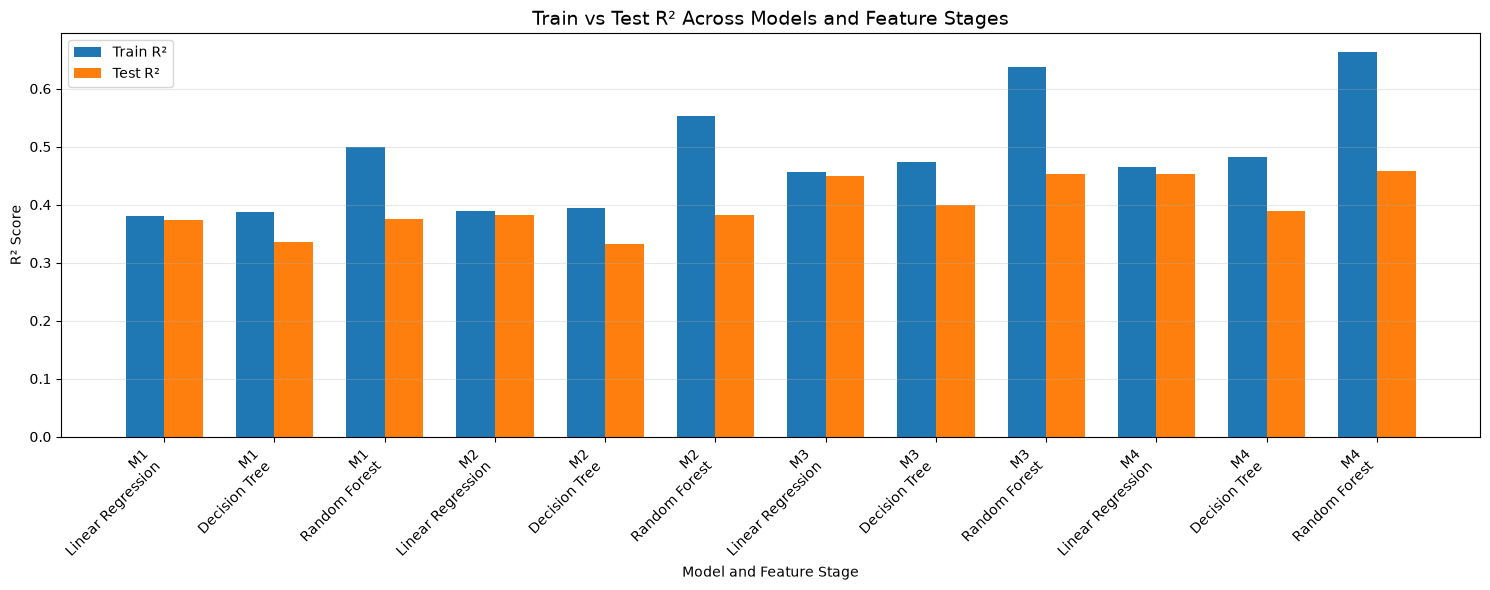

In [222]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare labels
labels = comparison_df["Stage"] + "\n" + comparison_df["Model"]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(15, 6))

# Plot Train and Test R²
ax.bar(x - width/2, comparison_df["Train_R2"],
       width, label="Train R²")

ax.bar(x + width/2, comparison_df["Test_R2"],
       width, label="Test R²")

# Formatting
ax.set_title("Train vs Test R² Across Models and Feature Stages",
             fontsize=14)

ax.set_xlabel("Model and Feature Stage")
ax.set_ylabel("R² Score")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [238]:
PROJECT_ROOT = Path("..").resolve()

MODELING_DIR = PROJECT_ROOT / "outputs" / "modeling"

plt.savefig(
    MODELING_DIR / "train_vs_test_r2.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

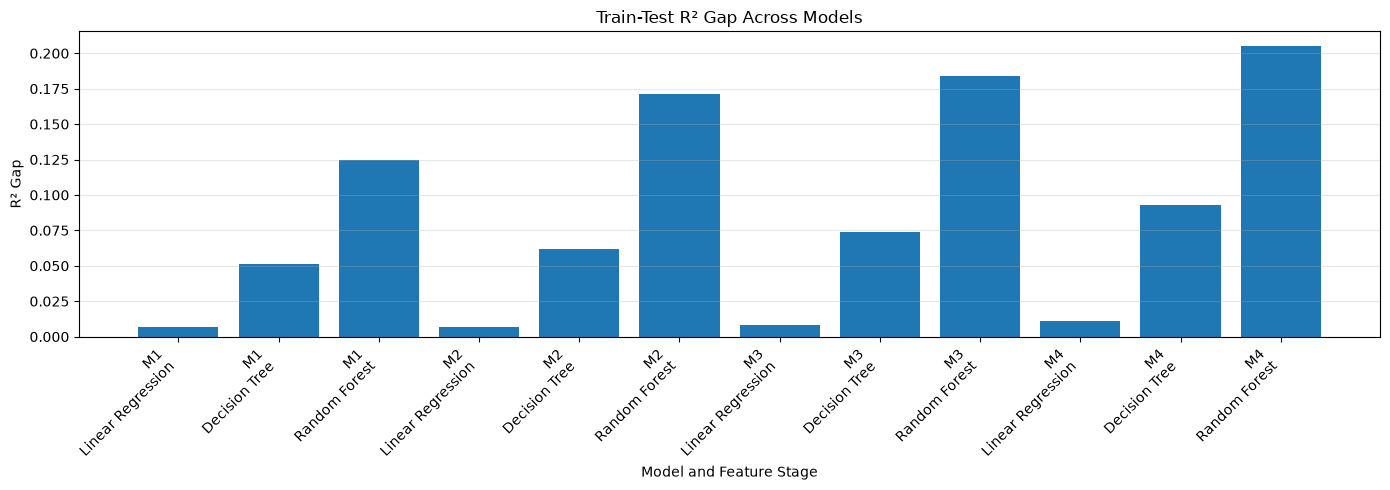

In [239]:
# Calculate the difference between training and test R²
comparison_df["R2_Gap"] = (
    comparison_df["Train_R2"] - comparison_df["Test_R2"]
)

# Plot R² gap
plt.figure(figsize=(14, 5))

labels = comparison_df["Stage"] + "\n" + comparison_df["Model"]

plt.bar(labels, comparison_df["R2_Gap"])

plt.title("Train-Test R² Gap Across Models")
plt.xlabel("Model and Feature Stage")
plt.ylabel("R² Gap")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    MODELING_DIR / "train_test_r2_gap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

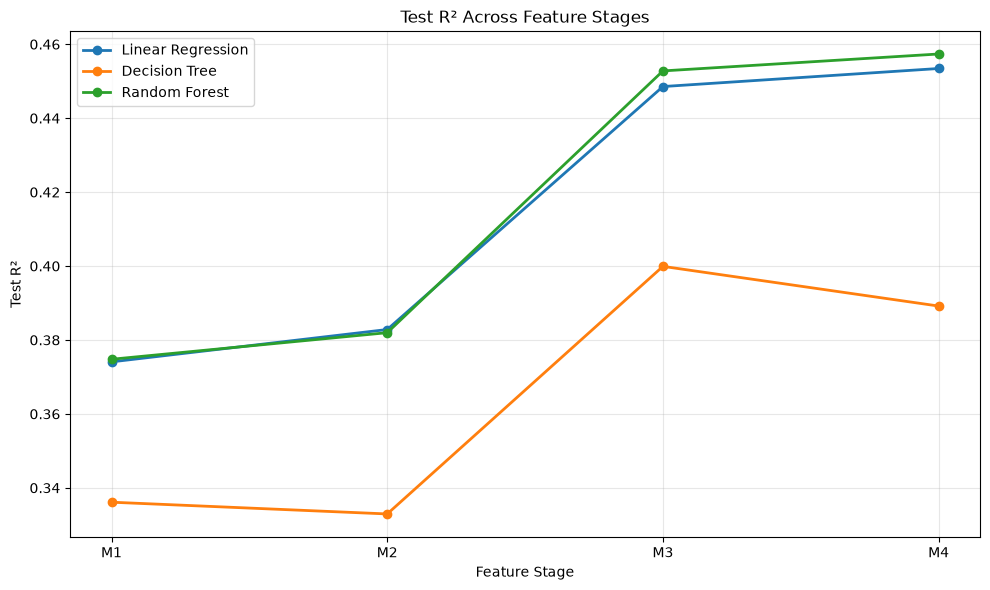

In [240]:
plt.figure(figsize=(10, 6))

for model_name in comparison_df["Model"].unique():
    model_data = comparison_df[
        comparison_df["Model"] == model_name
    ]

    plt.plot(
        model_data["Stage"],
        model_data["Test_R2"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title("Test R² Across Feature Stages")
plt.xlabel("Feature Stage")
plt.ylabel("Test R²")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    MODELING_DIR / "test_r2_across_stages.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Train and Test Performance Comparison

The comparison between training and test performance revealed differences in generalisation across the three regression algorithms.

Linear Regression demonstrated the most consistent performance across training and test datasets, with a small R² gap of 0.0109 in M4. Decision Tree showed moderate overfitting, while Random Forest achieved the highest test performance but also displayed the largest generalisation gap.

For Random Forest, the R² gap increased from 0.1249 in M1 to 0.2052 in M4. Although adding more feature categories improved test performance, the improvement was accompanied by increasing overfitting.

An important finding was that adding Personal Values & Wellbeing variables (M2 to M3) produced the largest improvement in test R² for Random Forest, increasing from 0.3820 to 0.4528.

In contrast, adding the remaining categories in M4 resulted in only a small additional improvement, suggesting diminishing predictive returns from the additional features.

## 10-Fold Cross-Validation

This section evaluates the stability and generalization
performance of the models using 10-fold cross-validation.

In [226]:
import inspect

print(inspect.signature(fit_hierarchical_imputer))
print(inspect.signature(apply_hierarchical_imputer))

(X_train, feature_info, min_group_size=30)
(X, imputation_stats, feature_info)


In [227]:
print(main_feature_info.shape)
print(main_feature_info.columns.tolist())
feature_info = main_feature_info.copy()

(241, 18)
['Variable', 'Feature_group', 'Variable_role', 'Model_status', 'Category', 'Column number', 'Data type', 'Missing count (NaN)', 'Missing percentage (NaN)', 'Unique values (excluding NaN)', 'Candidate special-code count', 'Candidate special-code details', 'Example values', 'Preliminary category', 'Measurement_type', 'Countries_with_valid_responses', 'Country_coverage_percentage', 'Respondents_with_valid_responses']


In [228]:
fit_hierarchical_imputer(
    X_train,
    feature_info,
    min_group_size=30
)

{'q288_global': np.float64(5.0),
 'q288_country': {'AND': np.float64(5.0),
  'ARG': np.float64(5.0),
  'ARM': np.float64(5.0),
  'AUS': np.float64(5.0),
  'BGD': np.float64(6.0),
  'BOL': np.float64(5.0),
  'BRA': np.float64(4.0),
  'CAN': np.float64(6.0),
  'CHL': np.float64(5.0),
  'CHN': np.float64(4.0),
  'COL': np.float64(5.0),
  'CYP': np.float64(5.0),
  'CZE': np.float64(5.0),
  'DEU': np.float64(5.0),
  'ECU': np.float64(5.0),
  'EGY': np.float64(5.0),
  'ETH': np.float64(5.0),
  'GBR': np.float64(5.0),
  'GRC': np.float64(5.0),
  'GTM': np.float64(6.0),
  'HKG': np.float64(5.0),
  'IDN': np.float64(4.0),
  'IND': np.float64(5.0),
  'IRN': np.float64(4.0),
  'IRQ': np.float64(4.0),
  'JOR': np.float64(4.0),
  'JPN': np.float64(4.0),
  'KAZ': np.float64(6.0),
  'KEN': np.float64(5.0),
  'KGZ': np.float64(5.0),
  'KOR': np.float64(5.0),
  'LBN': np.float64(6.0),
  'LBY': np.float64(5.0),
  'MAC': np.float64(5.0),
  'MAR': np.float64(5.0),
  'MDV': np.float64(6.0),
  'MEX': np.flo

In [231]:
# Check the data and feature information needed for cross-validation

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Feature info shape:", main_feature_info.shape)

print("Missing values in X_train:", X_train.isna().sum().sum())
print("Country column exists:", "Country" in X_train.columns)
print("Q288 column exists:", "Q288" in X_train.columns)

X_train shape: (77360, 242)
y_train shape: (77360,)
Feature info shape: (241, 18)
Missing values in X_train: 670249
Country column exists: True
Q288 column exists: True


### 10-fold Cross-Validation

In [232]:
from sklearn.model_selection import KFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np
import pandas as pd

# Create 10 folds from the original training data
kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Get the first fold
train_idx, val_idx = next(kf.split(X_train))

X_fold_train = X_train.iloc[train_idx].copy()
X_fold_val = X_train.iloc[val_idx].copy()

y_fold_train = y_train.iloc[train_idx]
y_fold_val = y_train.iloc[val_idx]

print("Fold training shape:", X_fold_train.shape)
print("Fold validation shape:", X_fold_val.shape)

Fold training shape: (69624, 242)
Fold validation shape: (7736, 242)


In [233]:
# Fit imputation statistics using only fold training data
fold_imputation_stats = fit_hierarchical_imputer(
    X_fold_train,
    main_feature_info,
    min_group_size=30
)

# Apply the fitted imputer to both subsets
X_fold_train_imputed = apply_hierarchical_imputer(
    X_fold_train,
    fold_imputation_stats,
    main_feature_info
)

X_fold_val_imputed = apply_hierarchical_imputer(
    X_fold_val,
    fold_imputation_stats,
    main_feature_info
)

print(
    "Remaining missing values in fold training:",
    X_fold_train_imputed.isna().sum().sum()
)

print(
    "Remaining missing values in fold validation:",
    X_fold_val_imputed.isna().sum().sum()
)

Remaining missing values in fold training: 0
Remaining missing values in fold validation: 0


In [234]:
features = stage_features["M4"]

pipeline = Pipeline([
    ("preprocessor", create_preprocessor(features)),
    ("model", clone(models["Random Forest"]))
])

pipeline.fit(
    X_fold_train_imputed[features],
    y_fold_train
)

fold_predictions = pipeline.predict(
    X_fold_val_imputed[features]
)

print("Fold R²:", round(r2_score(y_fold_val, fold_predictions), 4))
print("Fold MAE:", round(mean_absolute_error(y_fold_val, fold_predictions), 4))
print(
    "Fold RMSE:",
    round(np.sqrt(mean_squared_error(y_fold_val, fold_predictions)), 4)
)

Fold R²: 0.4513
Fold MAE: 1.2006
Fold RMSE: 1.6509


In [235]:
cv_results = []

kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train), start=1
):

    print(f"Running fold {fold}/10")

    X_fold_train = X_train.iloc[train_idx].copy()
    X_fold_val = X_train.iloc[val_idx].copy()

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Fit imputation statistics using fold training data only
    fold_stats = fit_hierarchical_imputer(
        X_fold_train,
        main_feature_info,
        min_group_size=30
    )

    # Apply imputation to training and validation data
    X_fold_train_imp = apply_hierarchical_imputer(
        X_fold_train,
        fold_stats,
        main_feature_info
    )

    X_fold_val_imp = apply_hierarchical_imputer(
        X_fold_val,
        fold_stats,
        main_feature_info
    )

    # Evaluate all model stages
    for stage, features in stage_features.items():

        for model_name, model in models.items():

            pipeline = Pipeline([
                ("preprocessor", create_preprocessor(features)),
                ("model", clone(model))
            ])

            pipeline.fit(
                X_fold_train_imp[features],
                y_fold_train
            )

            predictions = pipeline.predict(
                X_fold_val_imp[features]
            )

            cv_results.append({
                "Fold": fold,
                "Stage": stage,
                "Model": model_name,
                "R2": r2_score(y_fold_val, predictions),
                "MAE": mean_absolute_error(
                    y_fold_val, predictions
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(y_fold_val, predictions)
                )
            })

cv_results_df = pd.DataFrame(cv_results)

print("\nCross-validation completed.")
print("Total evaluations:", len(cv_results_df))

Running fold 1/10
Running fold 2/10
Running fold 3/10
Running fold 4/10
Running fold 5/10
Running fold 6/10
Running fold 7/10
Running fold 8/10
Running fold 9/10
Running fold 10/10

Cross-validation completed.
Total evaluations: 120


In [236]:
# Calculate mean and standard deviation across 10 folds

cv_summary = (
    cv_results_df
    .groupby(["Stage", "Model"])
    .agg(
        R2_Mean=("R2", "mean"),
        R2_Std=("R2", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        RMSE_Mean=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std")
    )
    .reset_index()
)

# Sort by average R²
cv_summary = cv_summary.sort_values(
    "R2_Mean",
    ascending=False
)

cv_summary.round(4)

,Stage,Model,R2_Mean,R2_Std,MAE_Mean,MAE_Std,RMSE_Mean,RMSE_Std
11,M4,Random Forest,0.4596,0.0081,1.1904,0.0104,1.6473,0.0159
10,M4,Linear Regression,0.4584,0.0052,1.2118,0.0089,1.6490,0.0170
8,M3,Random Forest,0.4560,0.0091,1.1938,0.0105,1.6526,0.0159
7,M3,Linear Regression,0.4525,0.0054,1.2193,0.0087,1.6581,0.0176
6,M3,Decision Tree,0.4048,0.0134,1.2465,0.0125,1.7287,0.0214
9,M4,Decision Tree,0.3971,0.0095,1.2532,0.0121,1.7398,0.0158
4,M2,Linear Regression,0.3862,0.0084,1.3105,0.0102,1.7556,0.0175
5,M2,Random Forest,0.3844,0.0076,1.3019,0.0092,1.7582,0.0161
1,M1,Linear Regression,0.3782,0.0085,1.3196,0.0103,1.7669,0.0179
2,M1,Random Forest,0.3776,0.0078,1.3099,0.0094,1.7678,0.0159


In [241]:


cv_results_df.to_csv(
    MODELING_DIR / "WVS_10Fold_CV_Results.csv",
    index=False
)

cv_summary.to_csv(
    MODELING_DIR / "WVS_10Fold_CV_Summary.csv",
    index=False
)

print("Cross-validation results saved.")

Cross-validation results saved.


In [242]:
cv_summary.to_csv(
    MODELING_DIR / "WVS_10Fold_CV_Summary.csv",
    index=False
)

cv_results_df.to_csv(
    MODELING_DIR / "WVS_10Fold_CV_Results.csv",
    index=False
)

print("CV results saved successfully.")

CV results saved successfully.


In [243]:
# Compare CV and Test performance for M4

test_m4 = results_df[
    results_df["Stage"] == "M4"
].copy()

cv_m4 = cv_summary[
    cv_summary["Stage"] == "M4"
].copy()

performance_comparison = cv_m4.merge(
    test_m4,
    on=["Stage", "Model"],
    how="inner"
)

performance_comparison = performance_comparison[
    [
        "Model",
        "R2_Mean",
        "R2_Std",
        "R2",
        "MAE_Mean",
        "MAE",
        "RMSE_Mean",
        "RMSE"
    ]
]

performance_comparison = performance_comparison.rename(
    columns={
        "R2_Mean": "CV_R2_Mean",
        "R2_Std": "CV_R2_Std",
        "R2": "Test_R2",
        "MAE_Mean": "CV_MAE_Mean",
        "MAE": "Test_MAE",
        "RMSE_Mean": "CV_RMSE_Mean",
        "RMSE": "Test_RMSE"
    }
)

performance_comparison.round(4)

,Model,CV_R2_Mean,CV_R2_Std,Test_R2,CV_MAE_Mean,Test_MAE,CV_RMSE_Mean,Test_RMSE
0,Random Forest,0.4596,0.0081,0.4574,1.1904,1.1862,1.6473,1.6434
1,Linear Regression,0.4584,0.0052,0.4534,1.2118,1.2093,1.6490,1.6493
2,Decision Tree,0.3971,0.0095,0.3892,1.2532,1.2517,1.7398,1.7436


In [244]:
# Check the data before exporting

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

print("Feature metadata:", main_feature_info.shape)

print("Training index aligned:",
      X_train.index.equals(y_train.index))

print("Test index aligned:",
      X_test.index.equals(y_test.index))

Training features: (77360, 242)
Test features: (19340, 242)
Training target: (77360,)
Test target: (19340,)
Feature metadata: (241, 18)
Training index aligned: True
Test index aligned: True


In [245]:
from pathlib import Path

# Define processed data directory
PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Prepare training and test exports
train_export = X_train.copy()
train_export["Q49"] = y_train

test_export = X_test.copy()
test_export["Q49"] = y_test

# Export CSV files
train_export.to_csv(
    PROCESSED_DATA_DIR / "WVS_Train_Clean.csv"
)

test_export.to_csv(
    PROCESSED_DATA_DIR / "WVS_Test_Clean.csv"
)

main_feature_info.to_csv(
    PROCESSED_DATA_DIR / "WVS_Feature_Metadata.csv",
    index=False
)

print("Data export completed!")
print("Saved to:", PROCESSED_DATA_DIR)

Data export completed!
Saved to: c:\Users\aiqiu\Documents\Nackademin\ML\wvs_mlproject\data\processed


In [246]:
for file in PROCESSED_DATA_DIR.iterdir():
    if file.is_file():
        print(file.name, f"{file.stat().st_size / 1024 / 1024:.2f} MB")

WVS_Feature_Metadata.csv 0.05 MB
WVS_Test_Clean.csv 17.74 MB
WVS_Train_Clean.csv 70.95 MB
